In [46]:
%config InlineBackend.figure_format = "retina"

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    font_scale=0.9,
    rc={
        # Figure size and quality
        "figure.figsize": (17, 7),
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "figure.facecolor": "#FFFFFF",
        "axes.facecolor": "#FFFFFF",

        # Text and typography
        "text.color": "#222222",
        "axes.labelcolor": "#444444",
        "axes.titlecolor": "#222222",
        "xtick.color": "#555555",
        "ytick.color": "#555555",
        "axes.titlesize": 14,
        "axes.titleweight": "semibold",
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,

        # Square grid (horizontal + vertical)
        "axes.grid": True,
        "axes.grid.axis": "both",
        "axes.axisbelow": True,
        "grid.color": "#DDE2E8",
        "grid.alpha": 0.7,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",

        # Lines and markers
        "lines.linewidth": 2,
        "lines.markersize": 5,

        # Clean borders
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#DDE2E8",
        "legend.frameon": False,

        # Spacing
        "axes.titlepad": 12,
        "axes.labelpad": 8,
    }
)

In [47]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df.job_posted_date)
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)



In [48]:
df['job_title_short'].value_counts()

job_title_short
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Business Analyst              49063
Software Engineer             44929
Senior Data Engineer          44563
Senior Data Scientist         36957
Senior Data Analyst           29216
Machine Learning Engineer     14080
Cloud Engineer                12331
Name: count, dtype: int64

In [49]:
df['job_schedule_type'].value_counts().head(3)

job_schedule_type
Full-time     701727
Contractor     34793
Internship      8742
Name: count, dtype: int64

<Axes: ylabel='job_schedule_type'>

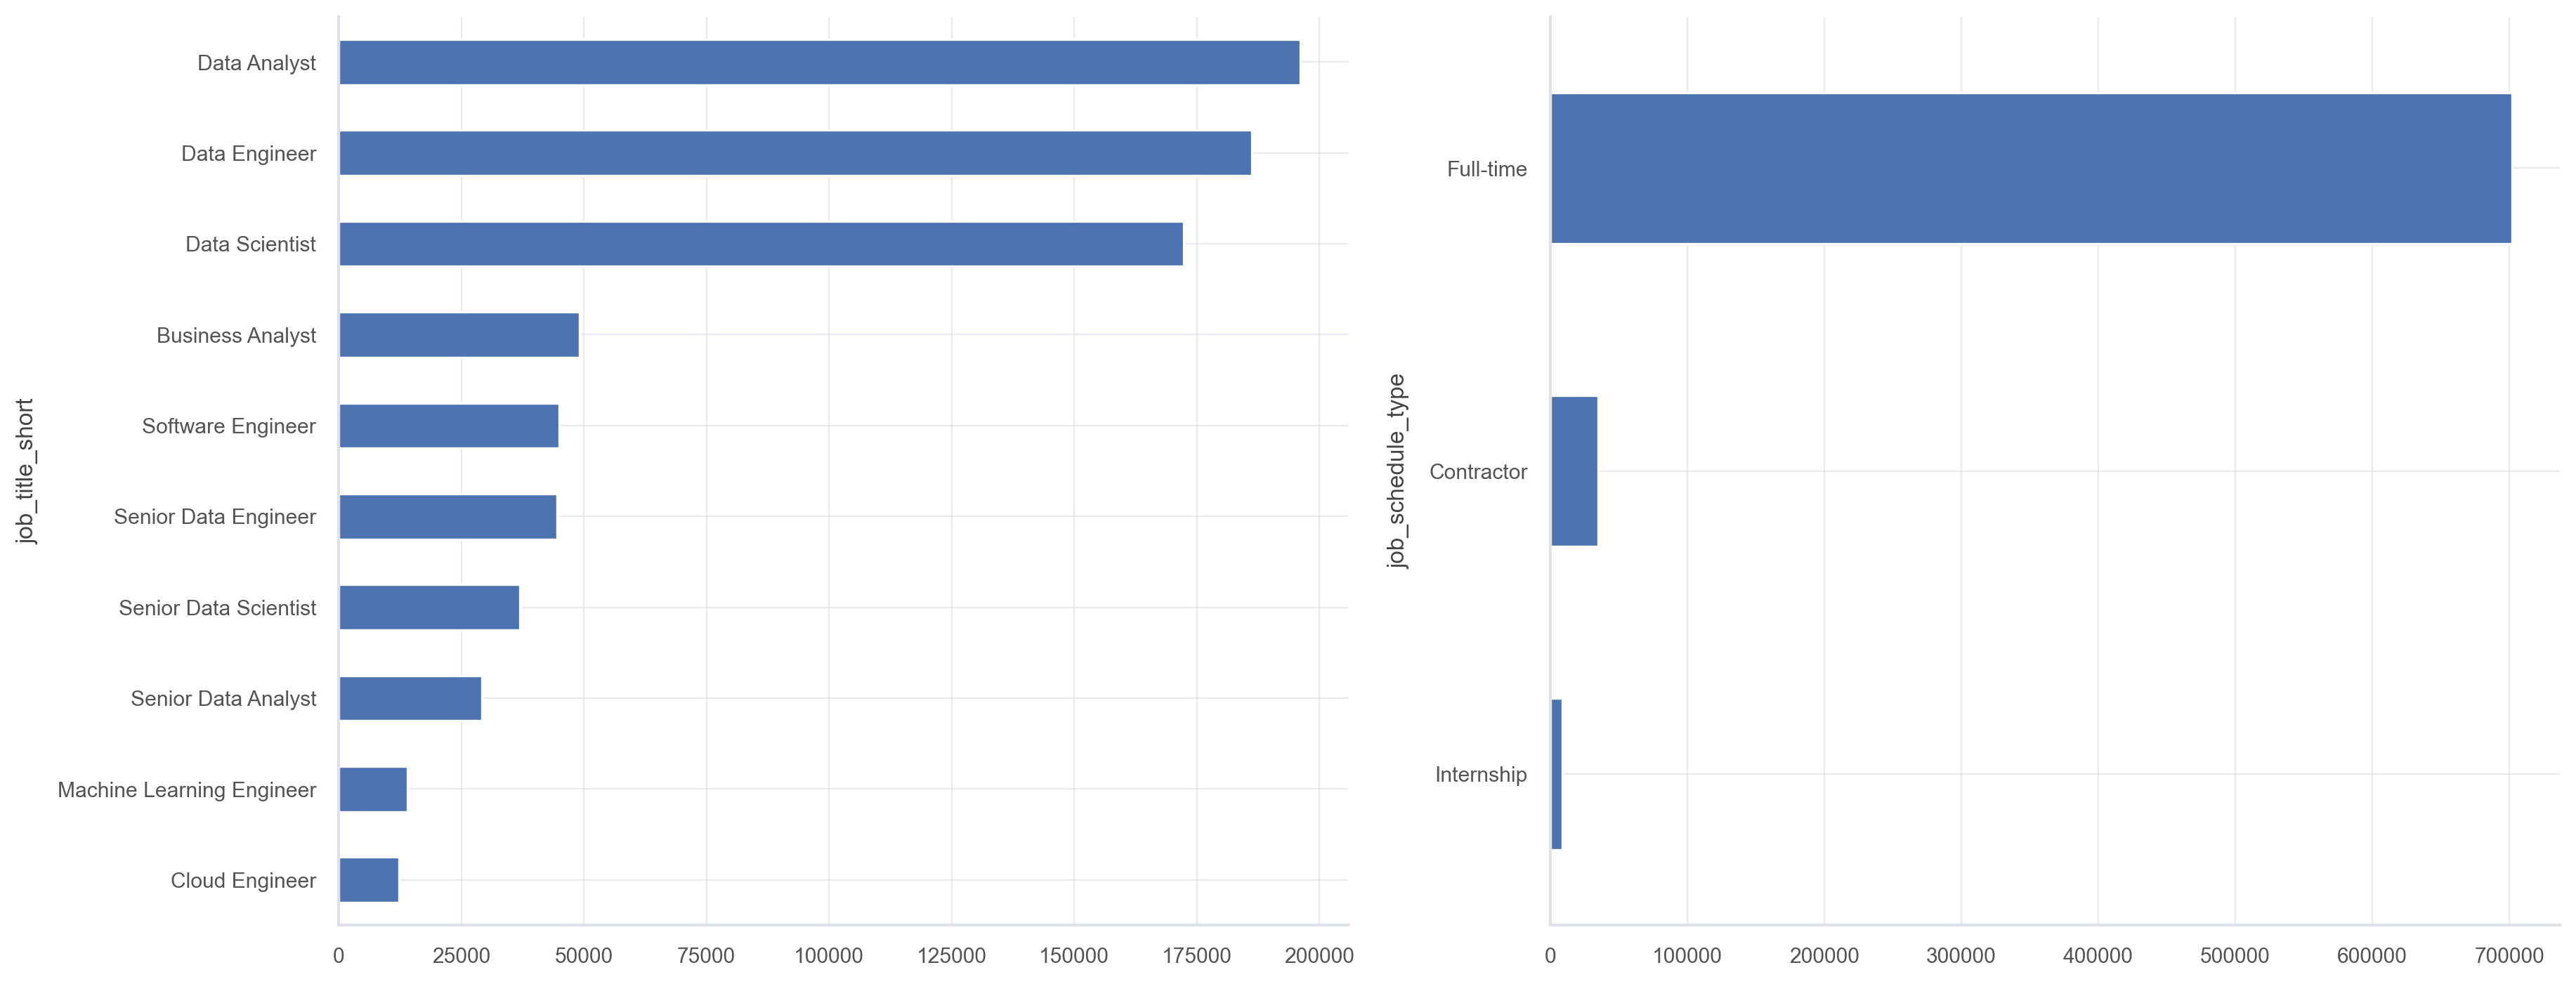

In [50]:
fig, ax = plt.subplots(1, 2)
df['job_title_short'].value_counts().sort_values(ascending=True).plot(kind='barh',ax=ax[0] , figsize=(17,7))
df['job_schedule_type'].value_counts().head(3).sort_values(ascending=True).plot(kind='barh', ax=ax[1], figsize=(17,7))

## Example 
### Top Skills For Each Data Jobs

In [51]:
df_exploded = df.explode('job_skills')
df_skills_count = df_exploded.groupby(['job_skills', 'job_title_short']).size().reset_index( name='skill_count').copy()
df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)
df_skills_count.reset_index(inplace=True)
df_skills_count.drop(columns='index', inplace=True)
df_skills_count


,job_skills,job_title_short,skill_count
0,python,Data Scientist,113711
1,sql,Data Engineer,113130
2,python,Data Engineer,108022
3,sql,Data Analyst,92428
4,sql,Data Scientist,78982
...,...,...,...
2251,webex,Senior Data Scientist,1
2252,codecommit,Business Analyst,1
2253,xamarin,Machine Learning Engineer,1
2254,mlr,Machine Learning Engineer,1


In [52]:
job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer']


0 Data Analyst
1 Data Scientist
2 Data Engineer


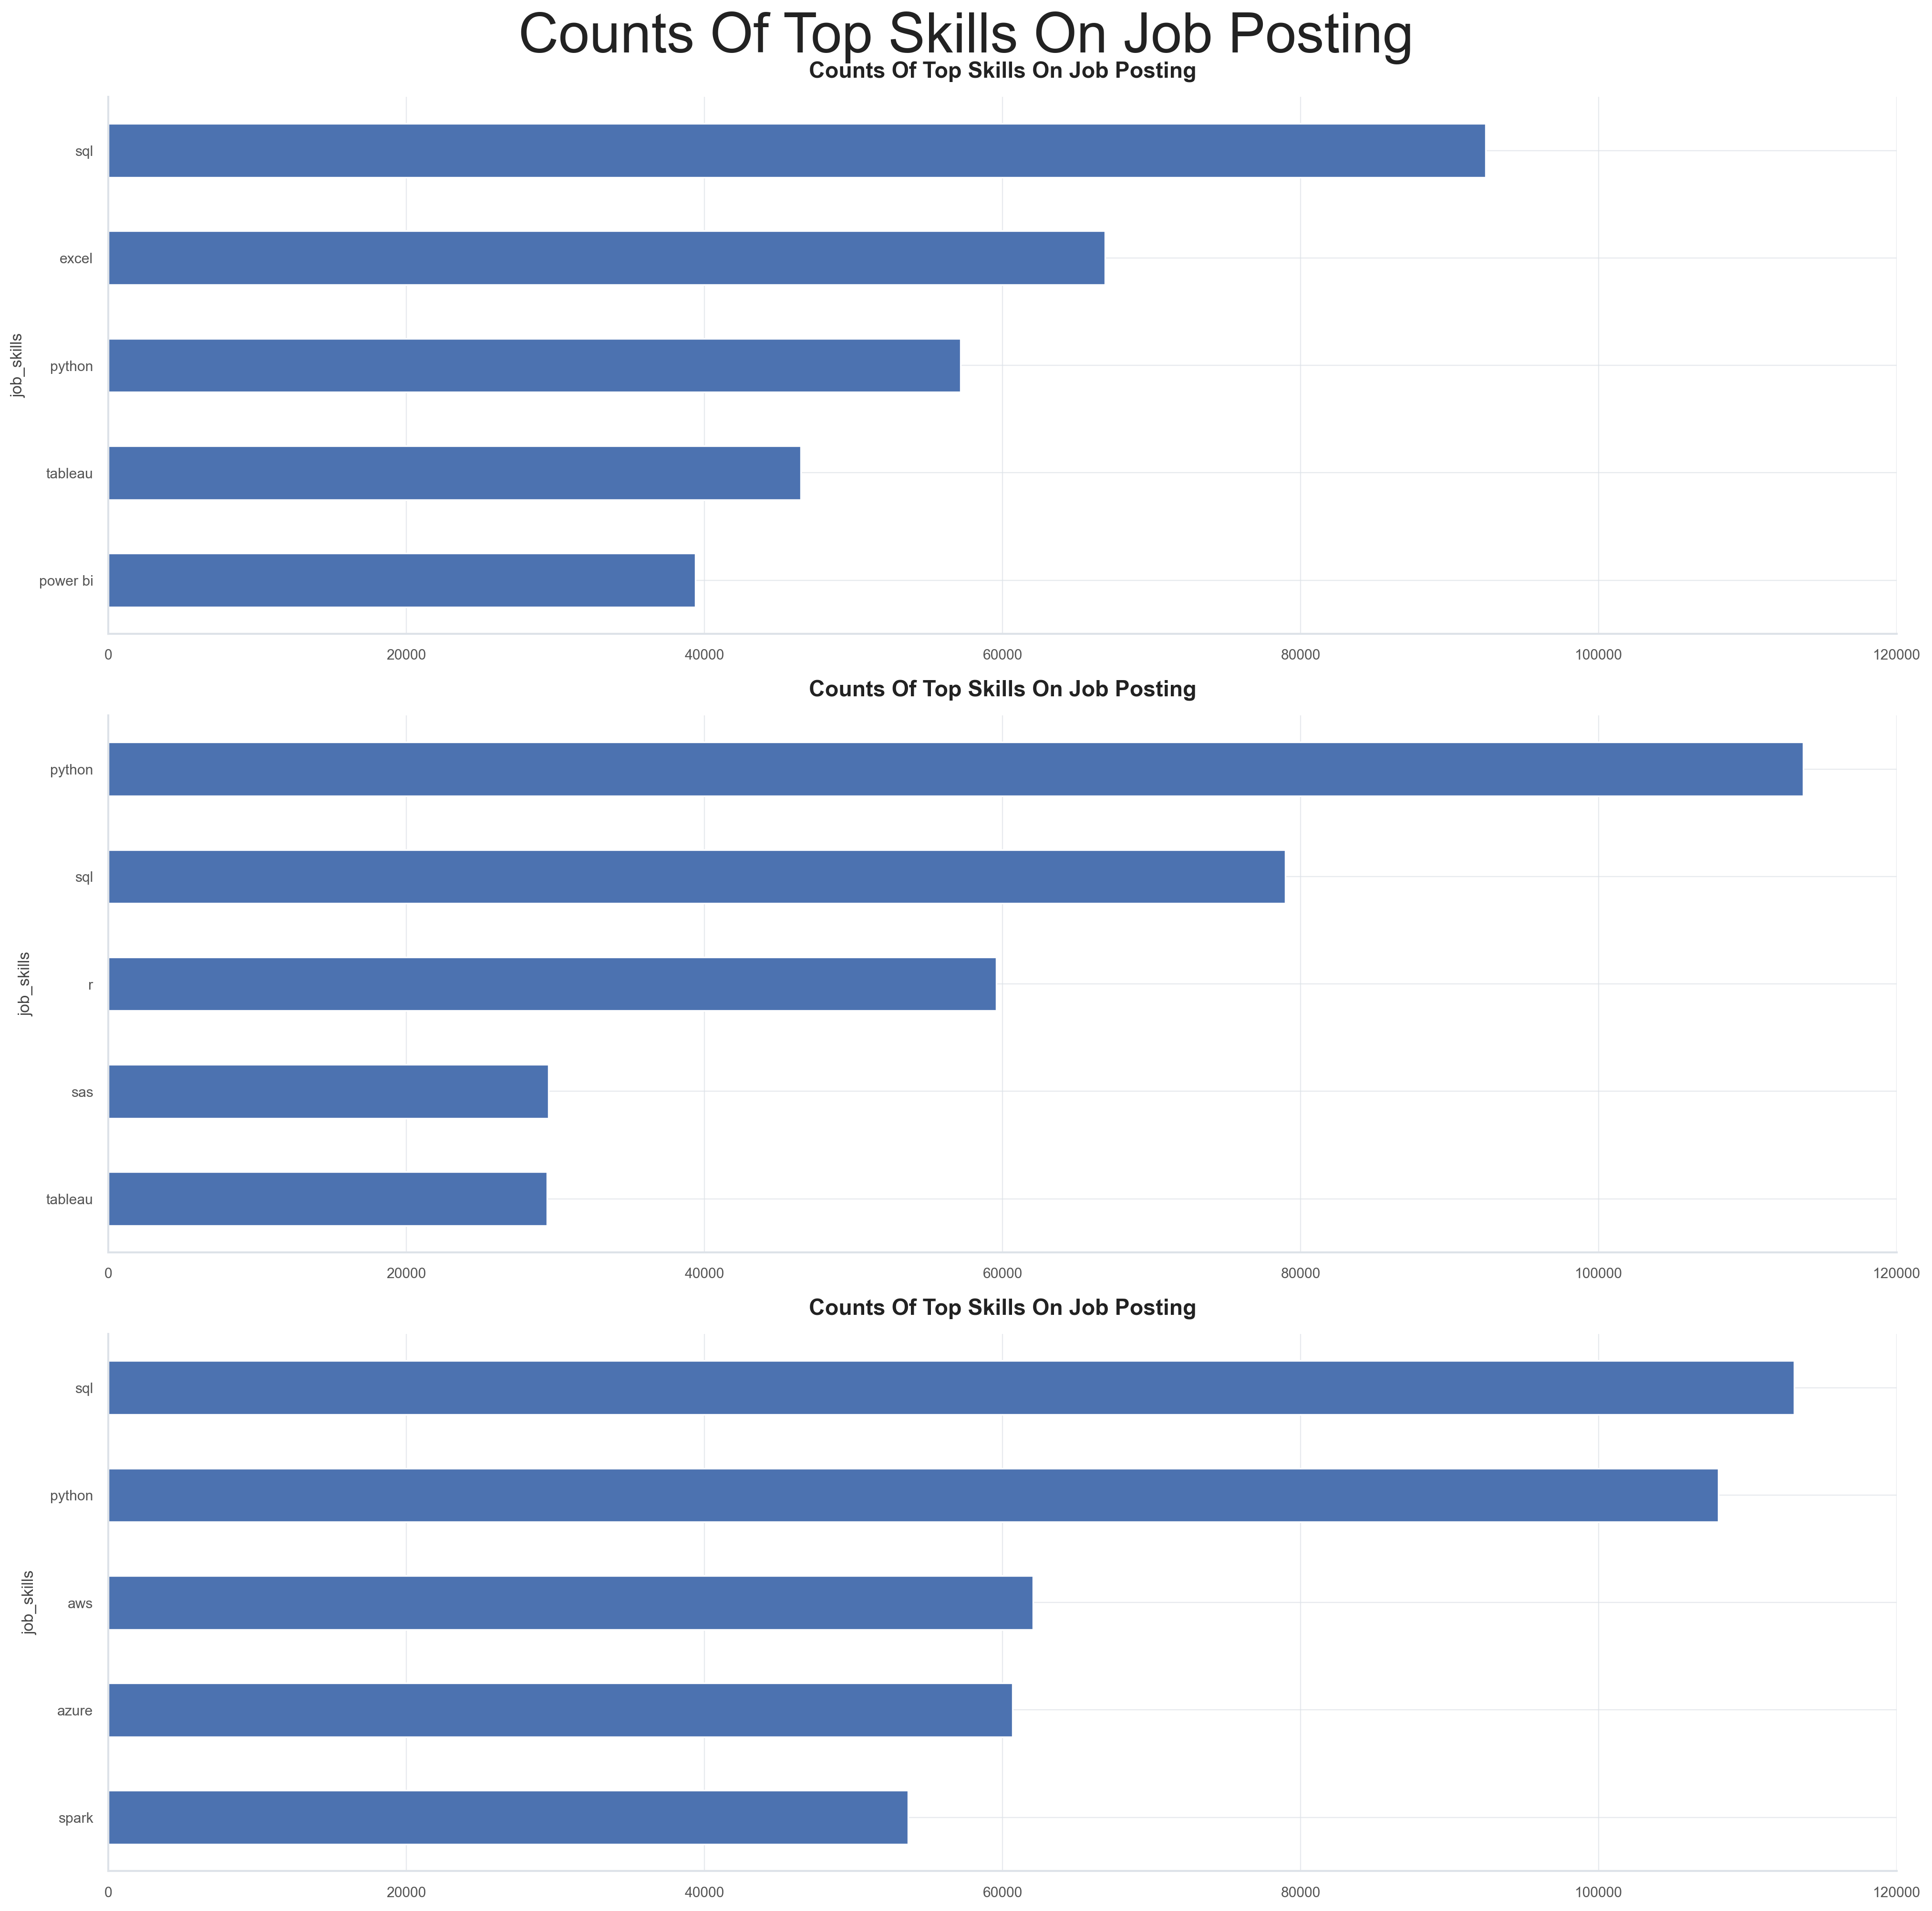

In [53]:
fig, ax = plt.subplots(3,1)

for i, job_title in enumerate(job_titles):
    print(i, job_title)
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head()
    df_plot.plot(kind='barh', ax=ax[i], x='job_skills',  y='skill_count', title=('Counts Of Top Skills On Job Posting'), figsize=(17,17), legend=False)
    ax[i].invert_yaxis()
    ax[i].set_xlim(0, 120000)

fig.suptitle('Counts Of Top Skills On Job Posting', fontsize=35)
fig.tight_layout()


#
#
#
#
# Pie Plot

<Axes: title={'center': 'Work From Home Statue'}>

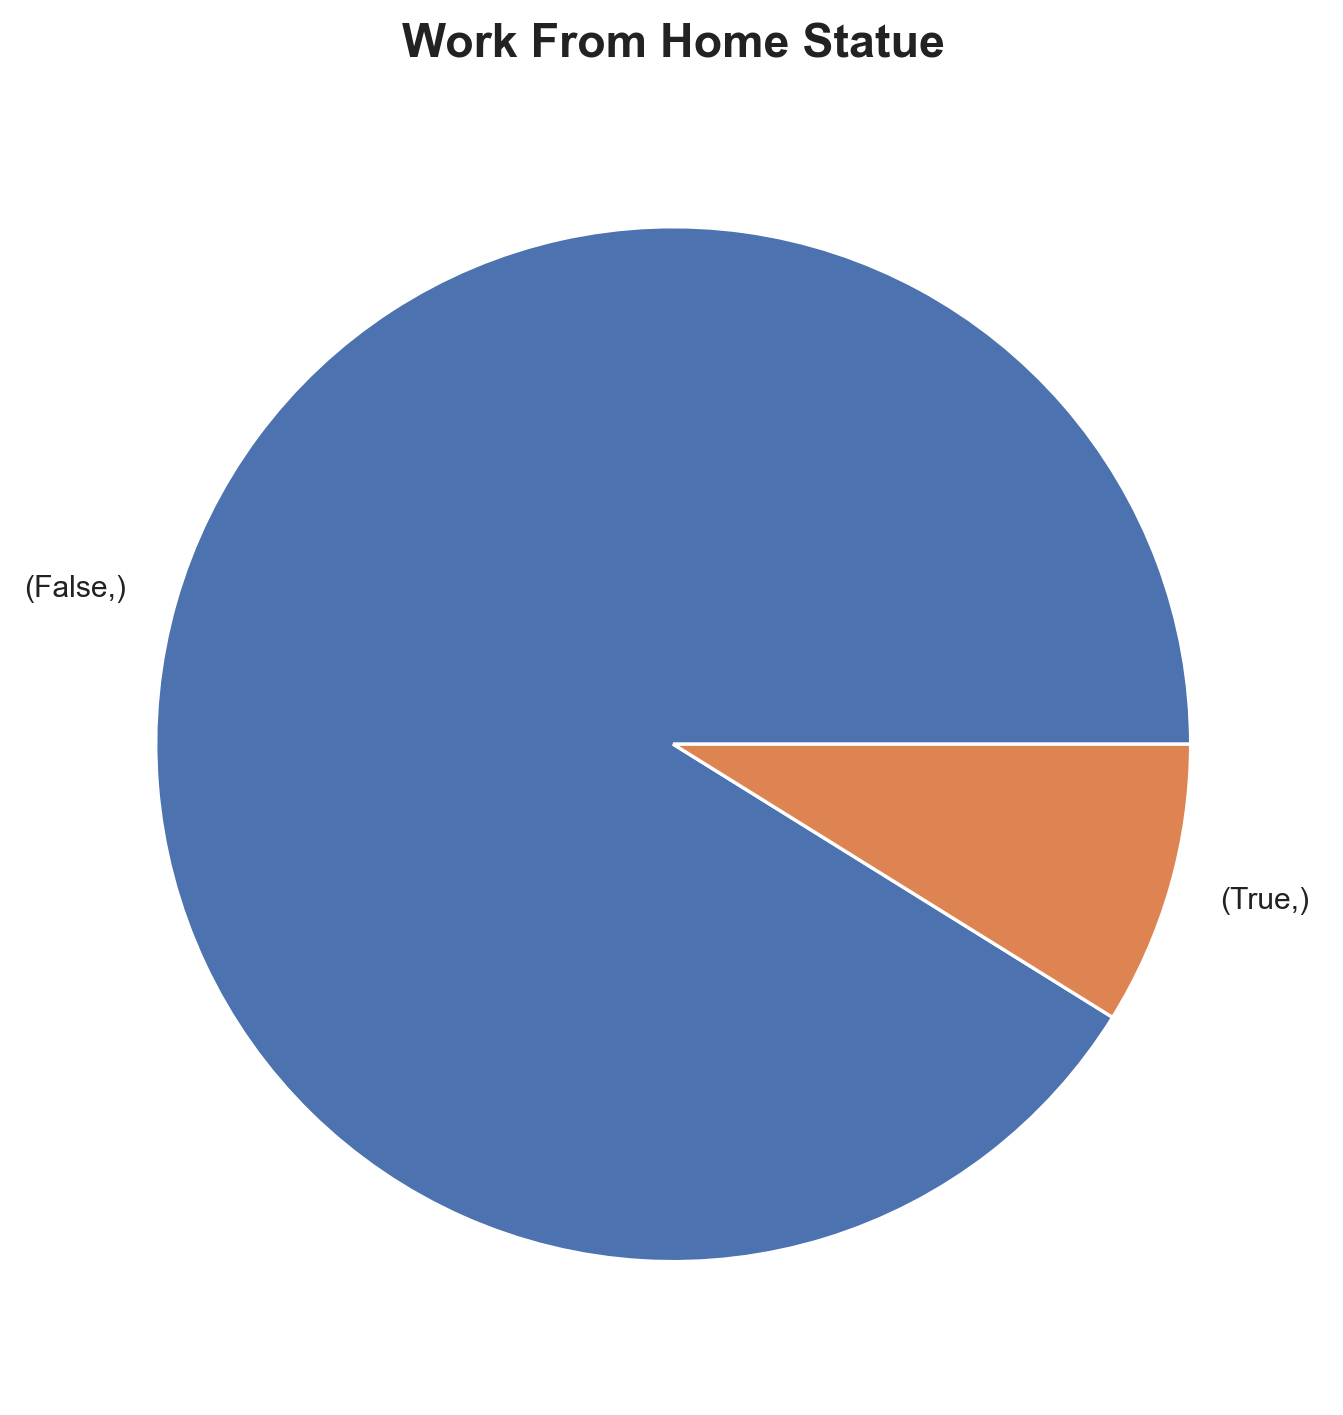

In [54]:
df[['job_work_from_home']].value_counts().plot(
    kind='pie',
    ylabel='',
    title='Work From Home Statue'  
    )

<Axes: title={'center': 'Work From Home Statue'}>

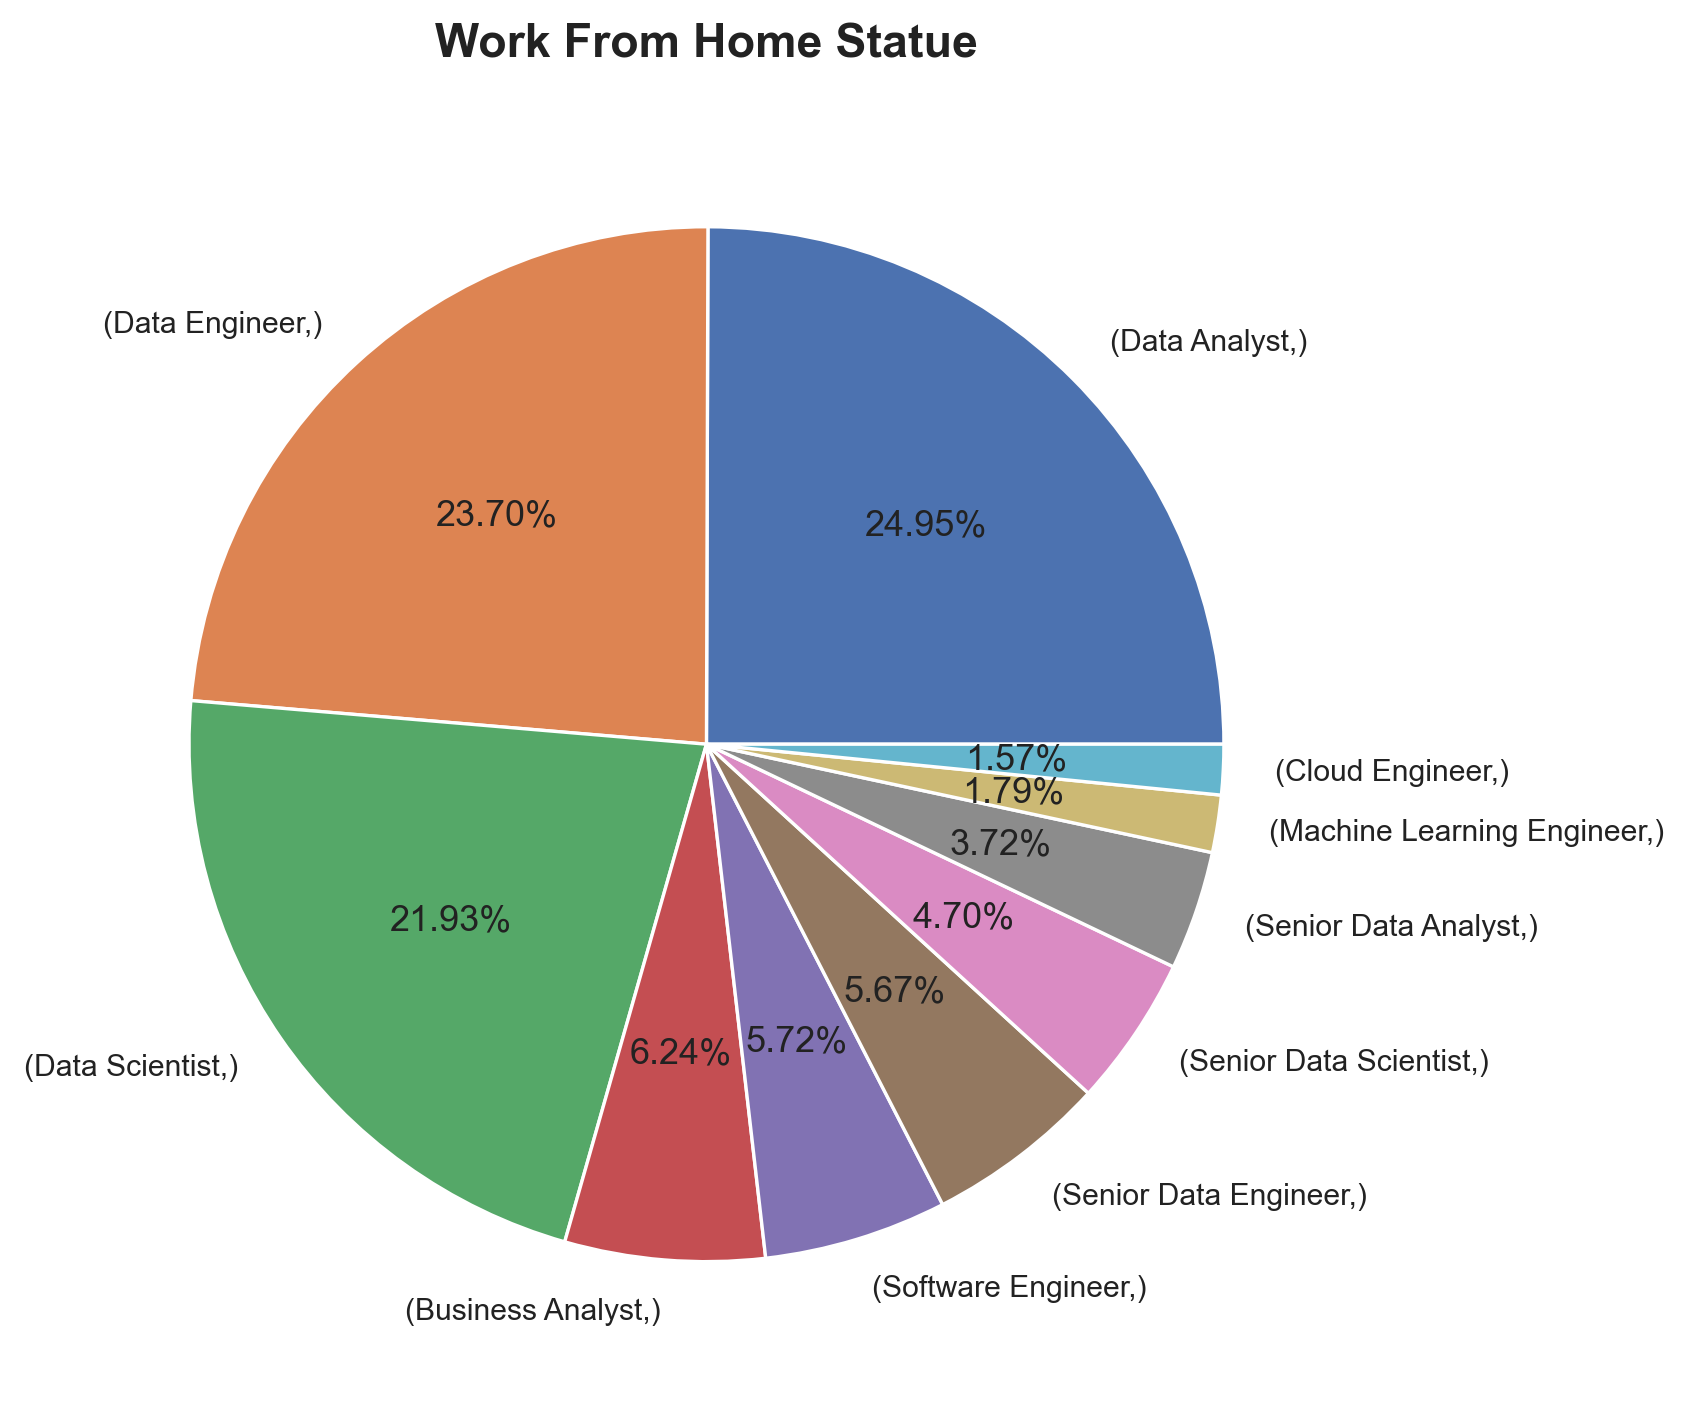

In [55]:
df[['job_title_short']].value_counts().plot(
    kind='pie',
    title='Work From Home Statue',
    ylabel='',
    startangle=0,
    autopct='%1.2f%%'
    )

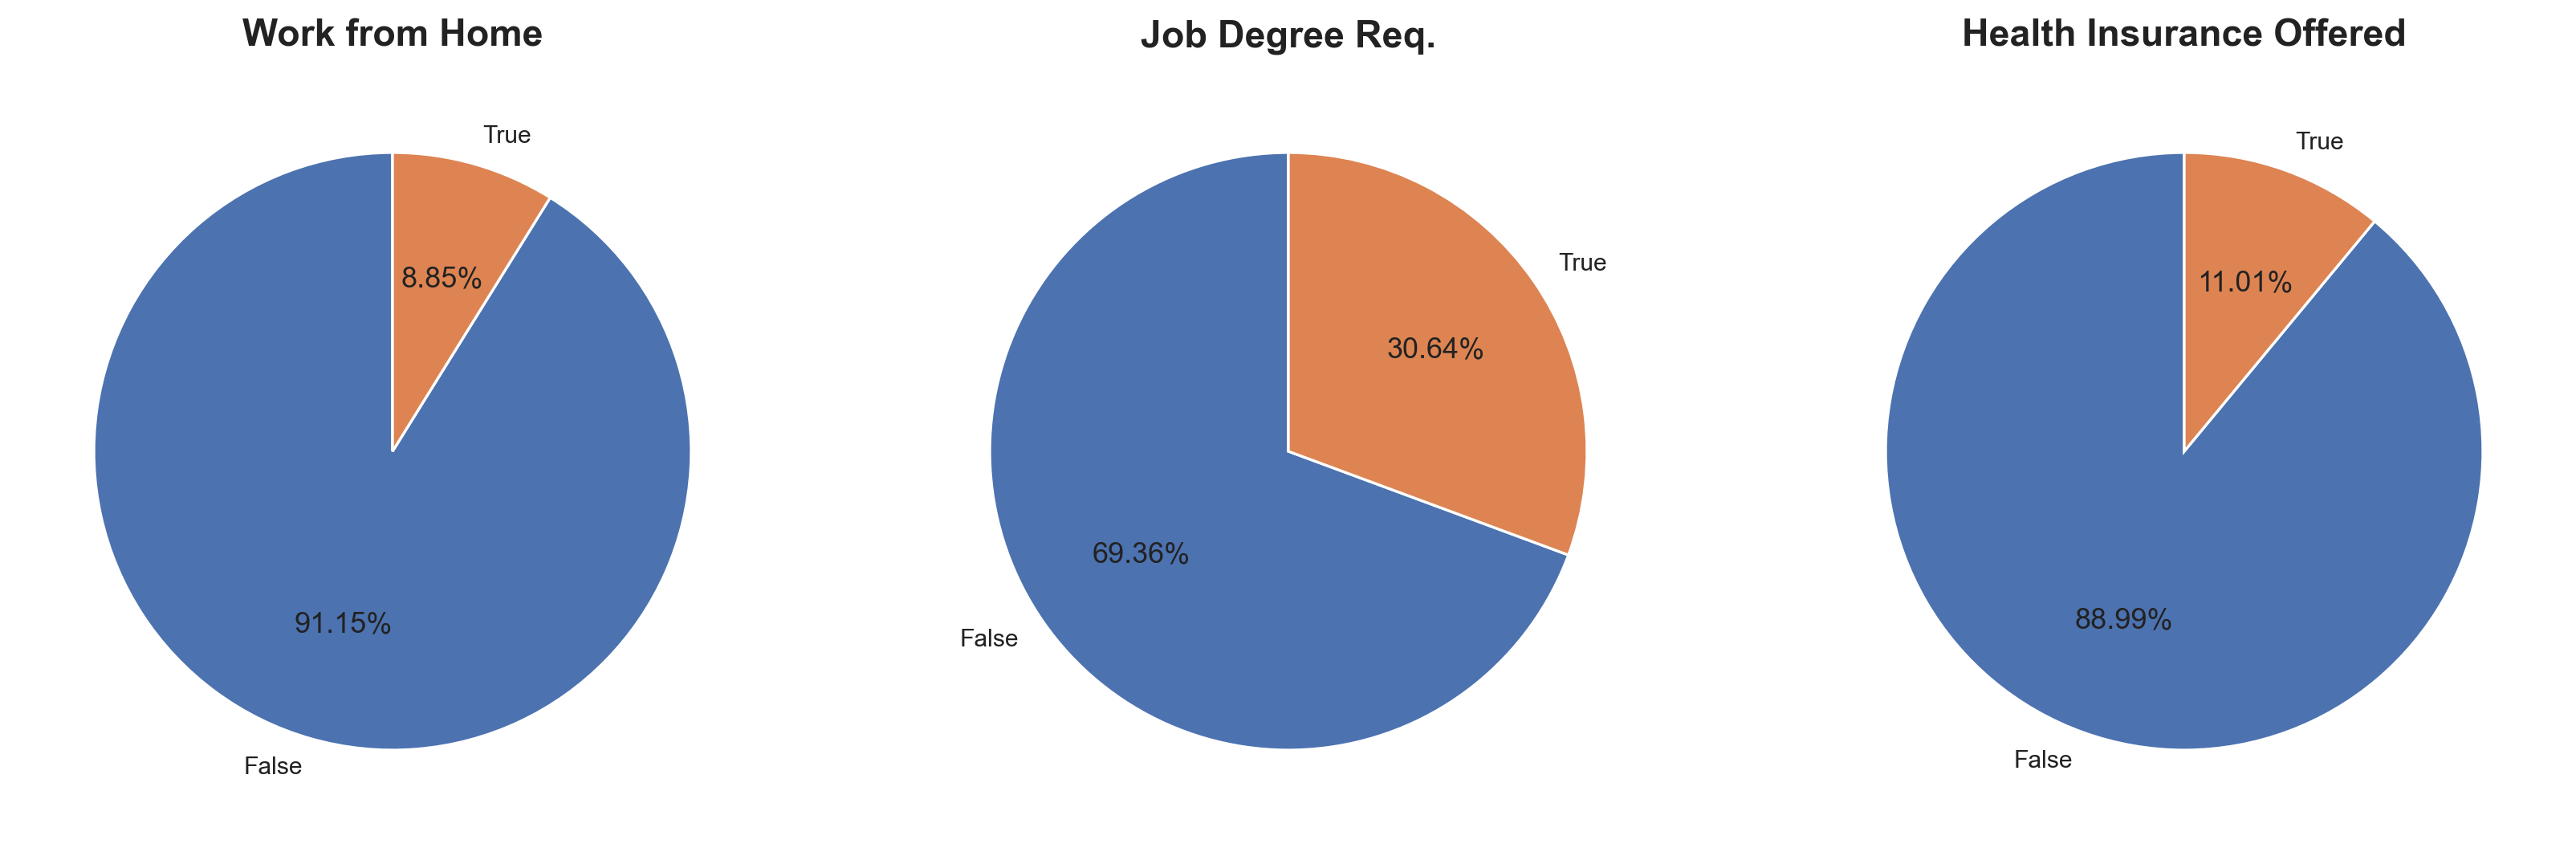

In [56]:
fig, ax = plt.subplots(1,3)

dict_column = {
    'job_work_from_home': 'Work from Home',
    'job_no_degree_mention': 'Job Degree Req.',
    'job_health_insurance': 'Health Insurance Offered'
}

for i, (column, title) in enumerate(dict_column.items()):
    df[column].value_counts().plot(
        kind='pie',
        title=title,
        ax=ax[i],
        ylabel='',
        startangle=90,
        autopct='%1.2f%%'
    )

# Scatter Plot

In [57]:
df_exploded = df_exploded[df_exploded['job_title_short'] == 'Data Analyst']

skill_stats = df_exploded.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)

skill_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(20)

skill_stats

,skill_count,median_salary
job_skills,,
sql,92428,92500.000000
excel,66860,84479.000000
python,57190,98500.000000
tableau,46455,95000.000000
power bi,39380,90000.000000
r,29996,92527.500000
sas,27998,90000.000000
powerpoint,13822,85000.000000
word,13562,80000.000000


# Exercice : Trending Skills

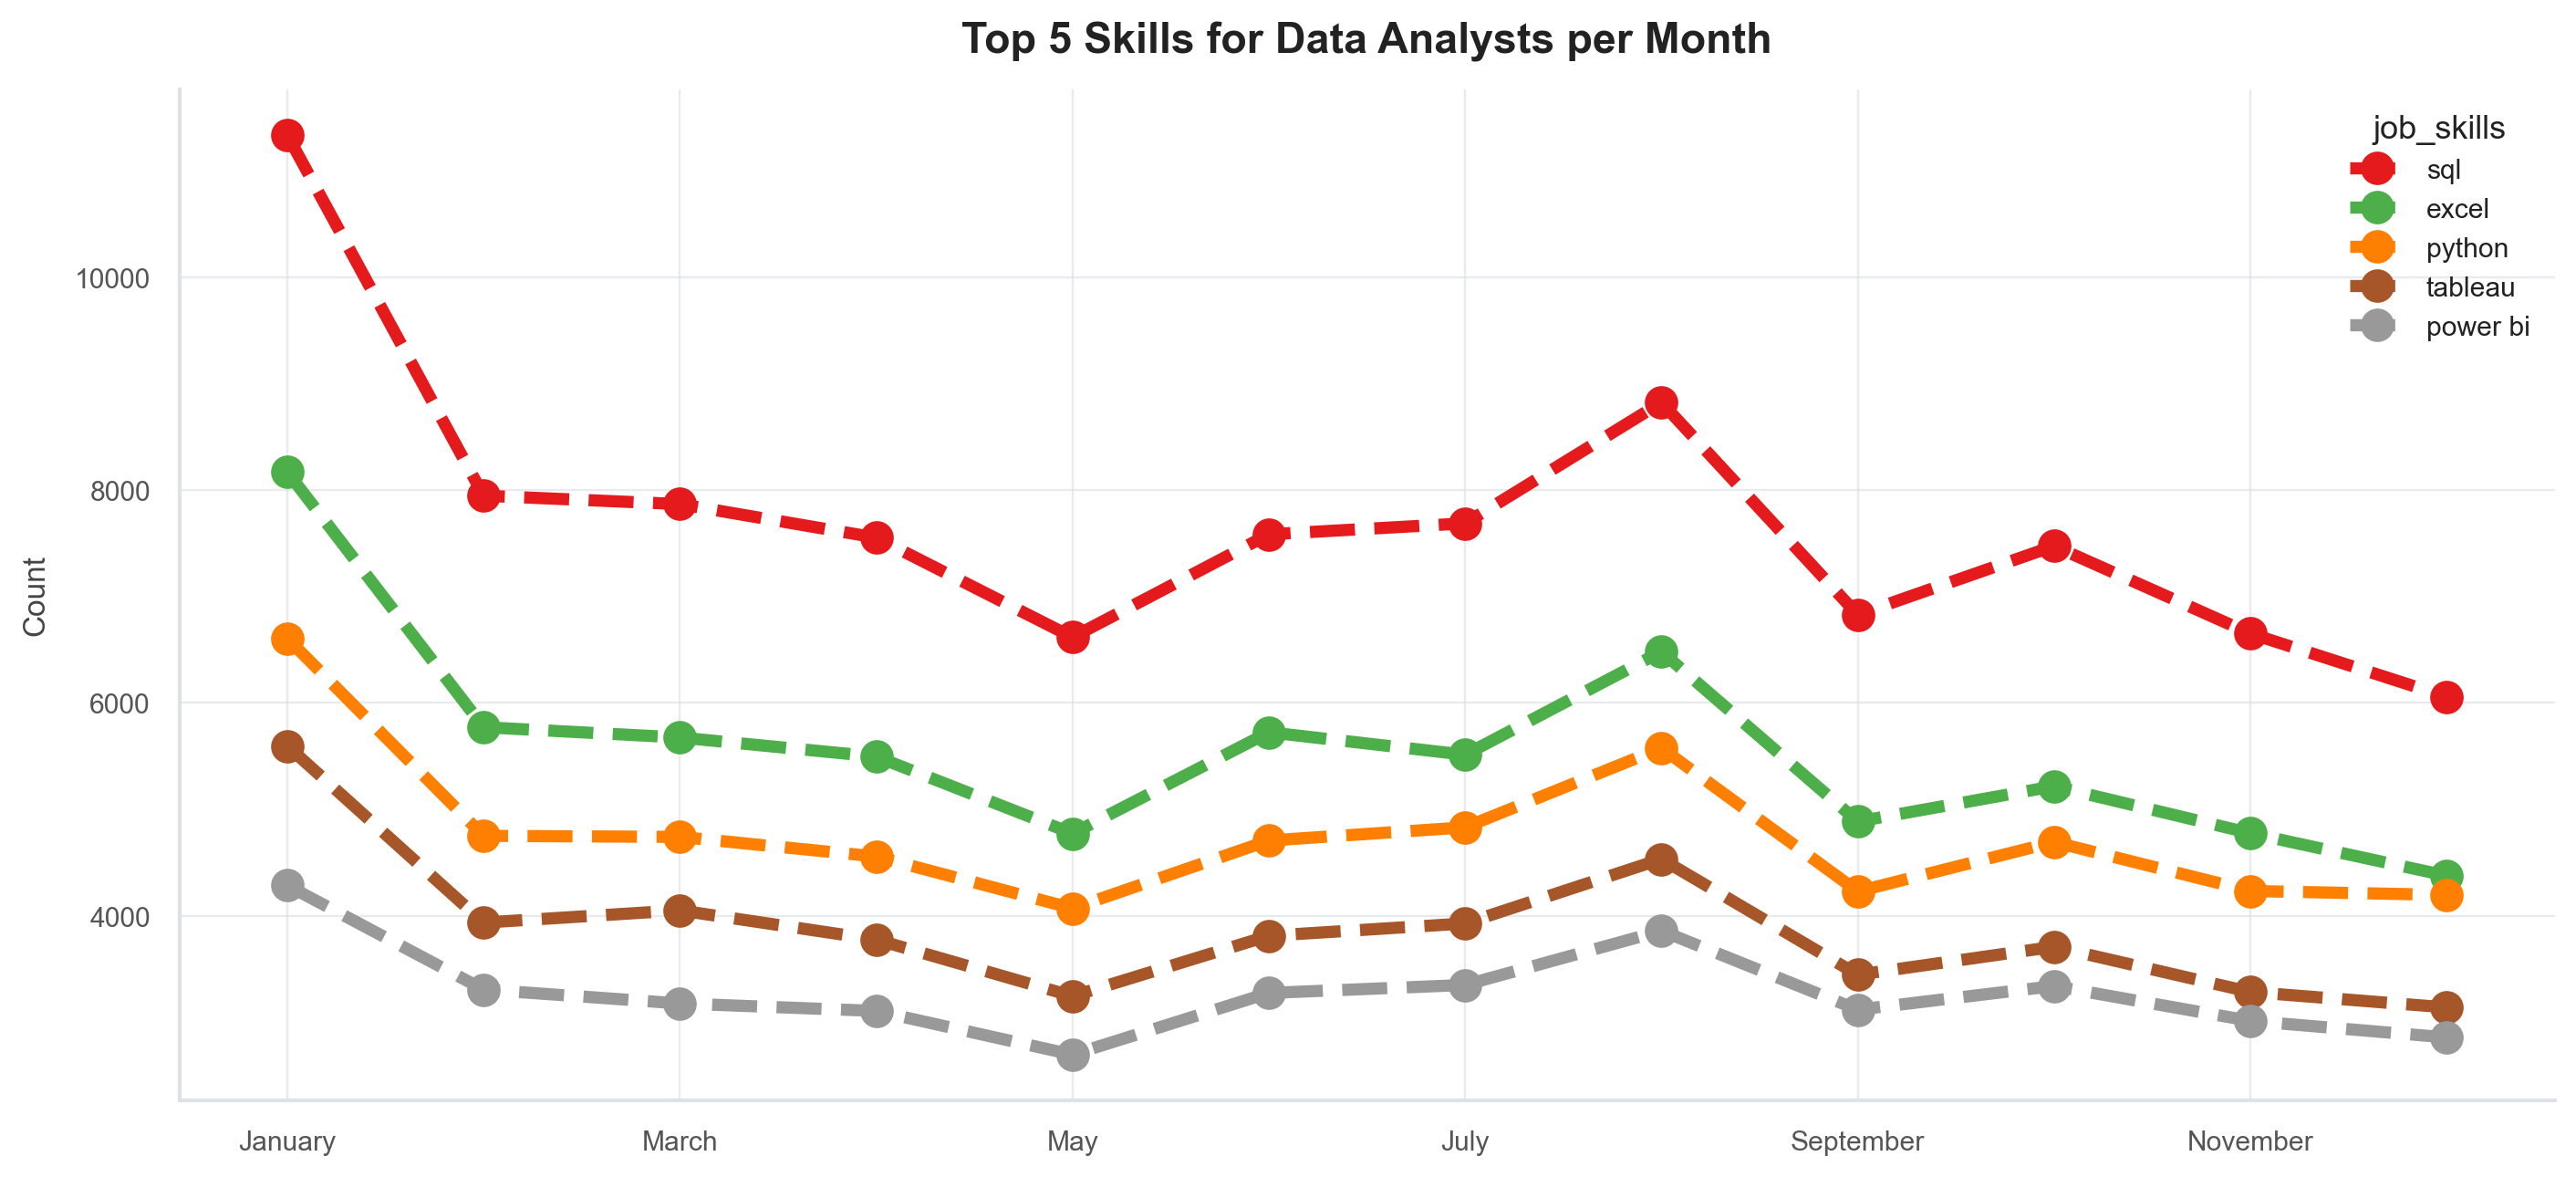

In [58]:
df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()
# create a new column for month number
df_DA['job_posted_month_no'] = df_DA['job_posted_date'].dt.month

# Explode the job_skills column and pivot
df_DA_explode = df_DA.explode('job_skills')
df_DA_pivot = df_DA_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

# sort the skills by count
df_DA_pivot.loc['Total'] = df_DA_pivot.sum()
df_DA_pivot = df_DA_pivot[df_DA_pivot.loc['Total'].sort_values(ascending=False).index]
df_DA_pivot = df_DA_pivot.drop('Total')

# Use month names for plotting
df_DA_pivot = df_DA_pivot.reset_index()
df_DA_pivot['job_posted_month'] = df_DA_pivot['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%B'))
df_DA_pivot = df_DA_pivot.set_index('job_posted_month')
df_DA_pivot = df_DA_pivot.drop(columns='job_posted_month_no')

df_DA_pivot.iloc[:, :5].plot(
    kind='line',
    linewidth=4,
    linestyle='--',
    colormap='Set1',
    marker='o', markersize=10,
    figsize=(14,6)
)

plt.title('Top 5 Skills for Data Analysts per Month')
plt.ylabel('Count')
plt.xlabel('')
plt.show()

In [59]:
skill_stats

,skill_count,median_salary
job_skills,,
sql,92428,92500.000000
excel,66860,84479.000000
python,57190,98500.000000
tableau,46455,95000.000000
power bi,39380,90000.000000
r,29996,92527.500000
sas,27998,90000.000000
powerpoint,13822,85000.000000
word,13562,80000.000000


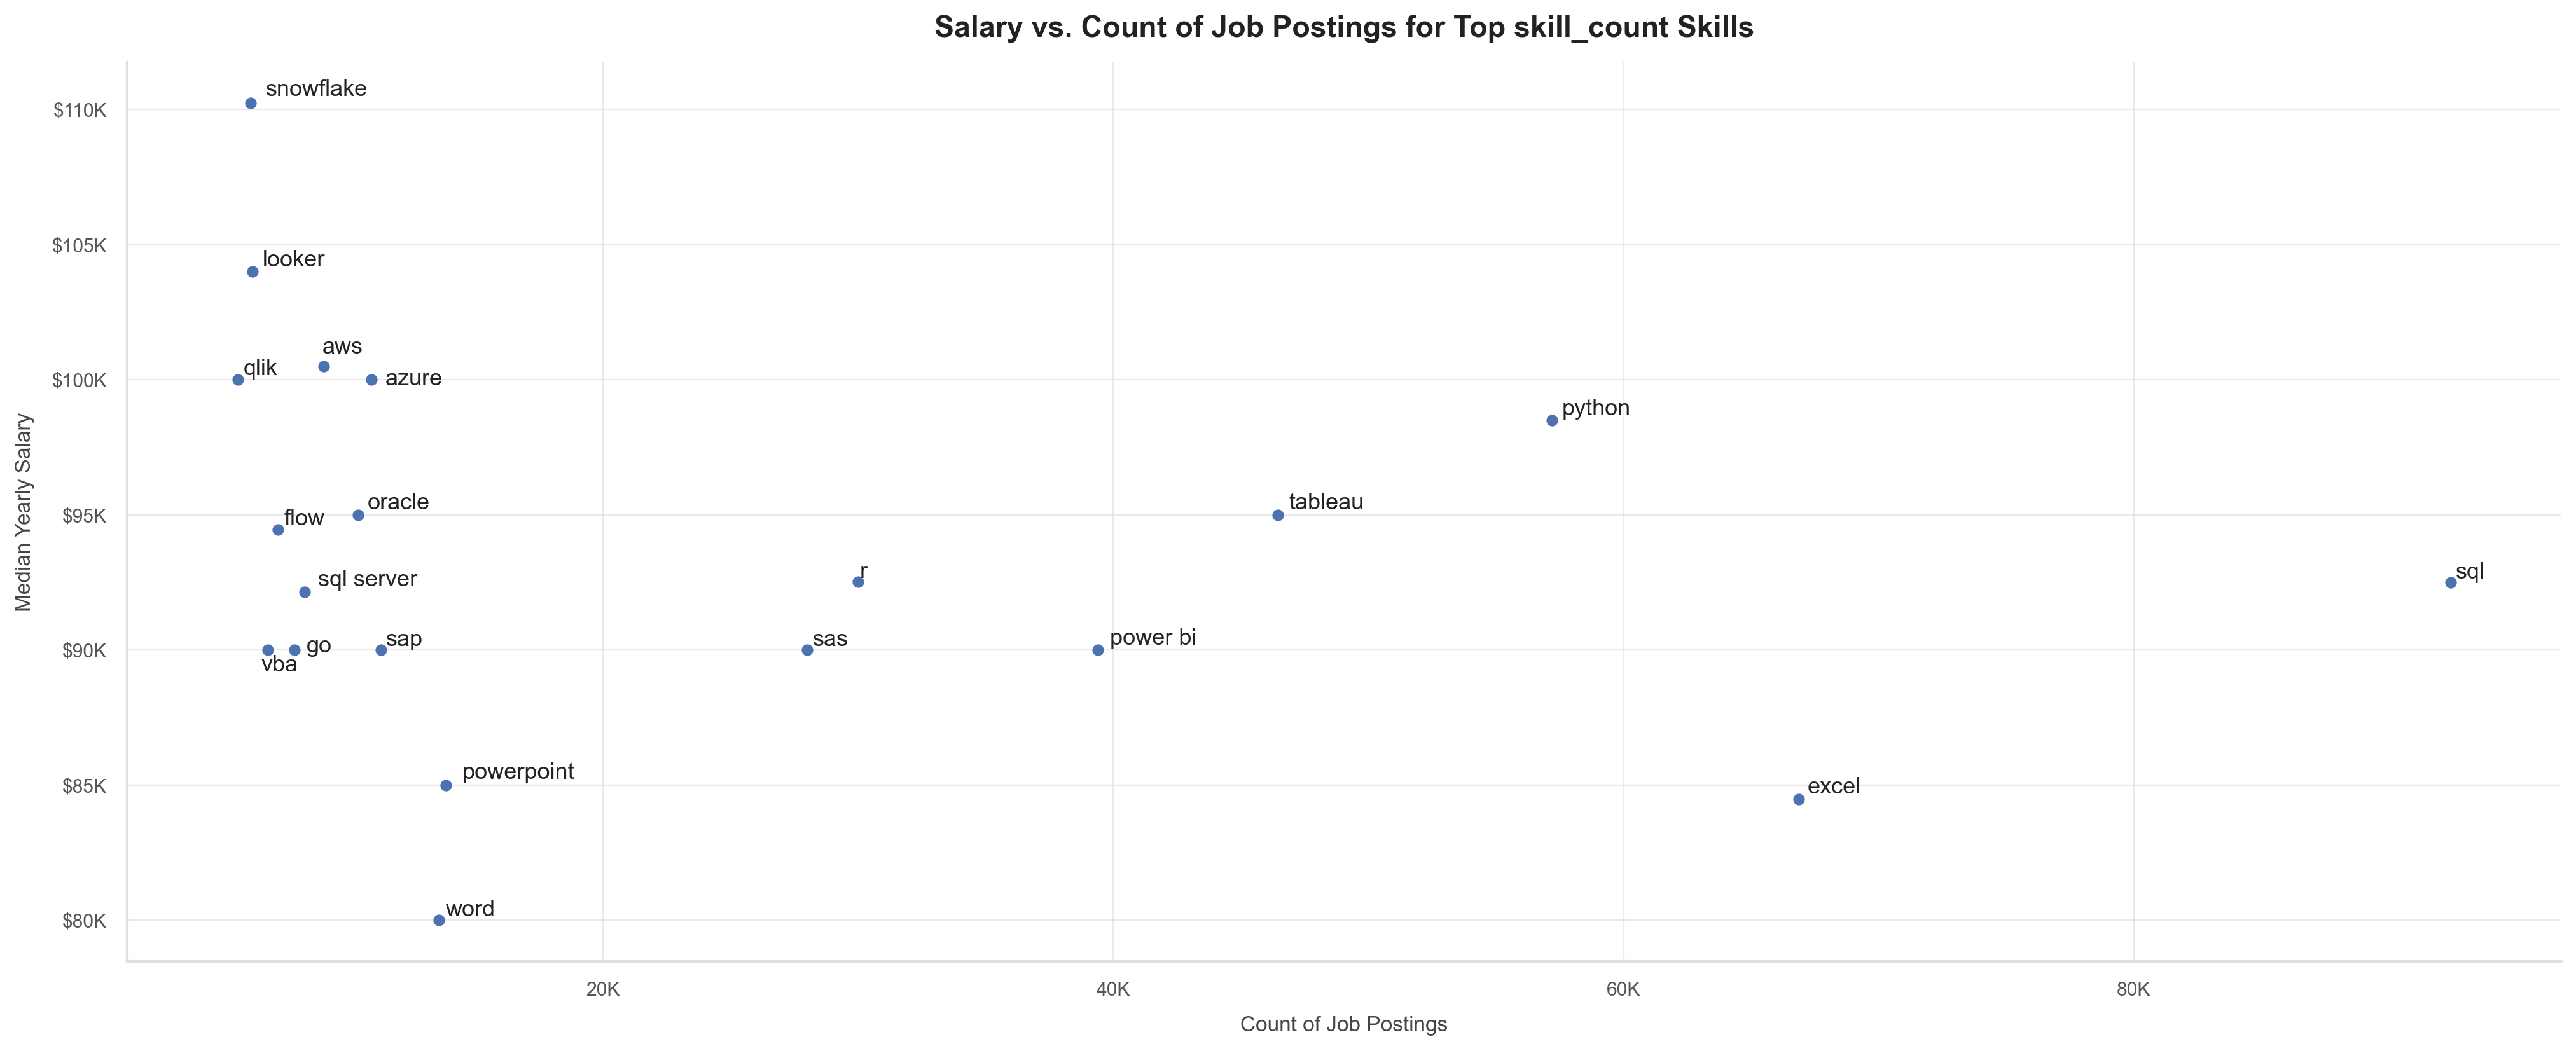

In [60]:
from adjustText import adjust_text

#fig, ax = plt.subplots()

skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')

texts =[]
for i, txt in enumerate(skill_stats.index):
    texts.append(plt.text(skill_stats['skill_count'].iloc[i], skill_stats['median_salary'].iloc[i], txt))

adjust_text(texts)

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x/1000)}K'))

plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary')
plt.title(f'Salary vs. Count of Job Postings for Top {'skill_count'} Skills')
plt.tight_layout()
plt.show()

# HisTograms . 

In [61]:
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()

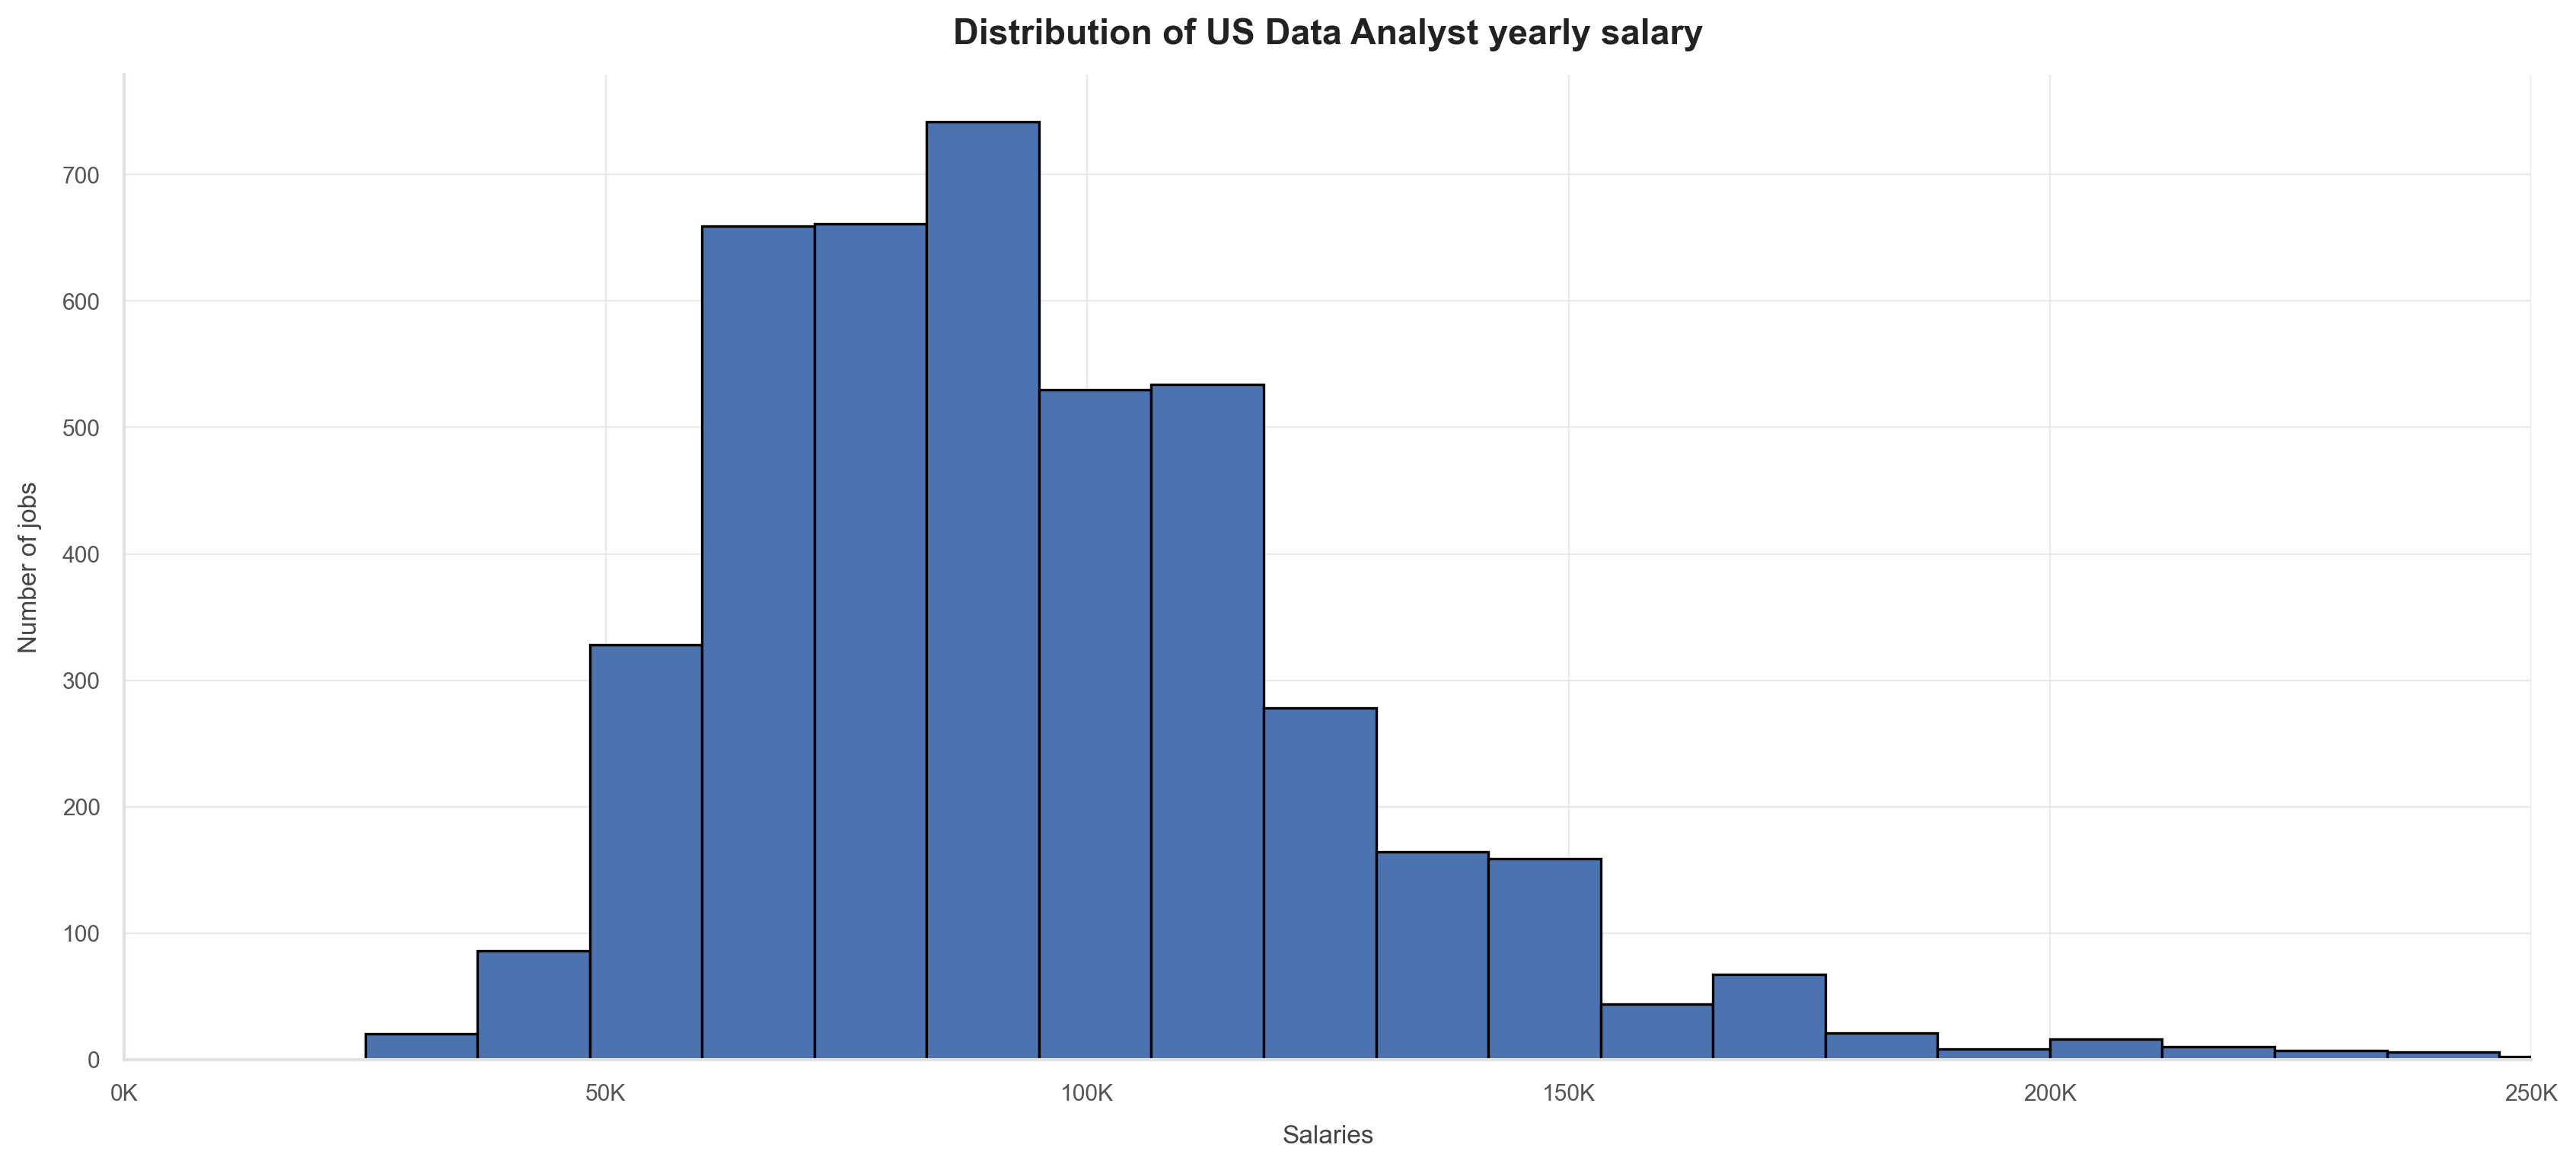

In [62]:
df_DA_US['salary_year_avg'].plot(
    kind='hist',
    title='Distribution of US Data Analyst yearly salary',
    xlabel='Salaries',
    ylabel='Number of jobs',
    bins=30,
    edgecolor='black',
    xlim=(0,250000)

)
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x/1000)}K'))

# Box Plots

In [63]:
# Only get data analyst jobs
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()

# Drop NaN values from the column for plotting
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])

df_DA_US['salary_year_avg'].sample(10)



100532    163000.0
15372      73696.0
295891     95000.0
321346    156500.0
215874     75000.0
332738    100700.0
662134     90000.0
518452    180000.0
297910    103200.0
120324    115000.0
Name: salary_year_avg, dtype: float64

<Axes: >

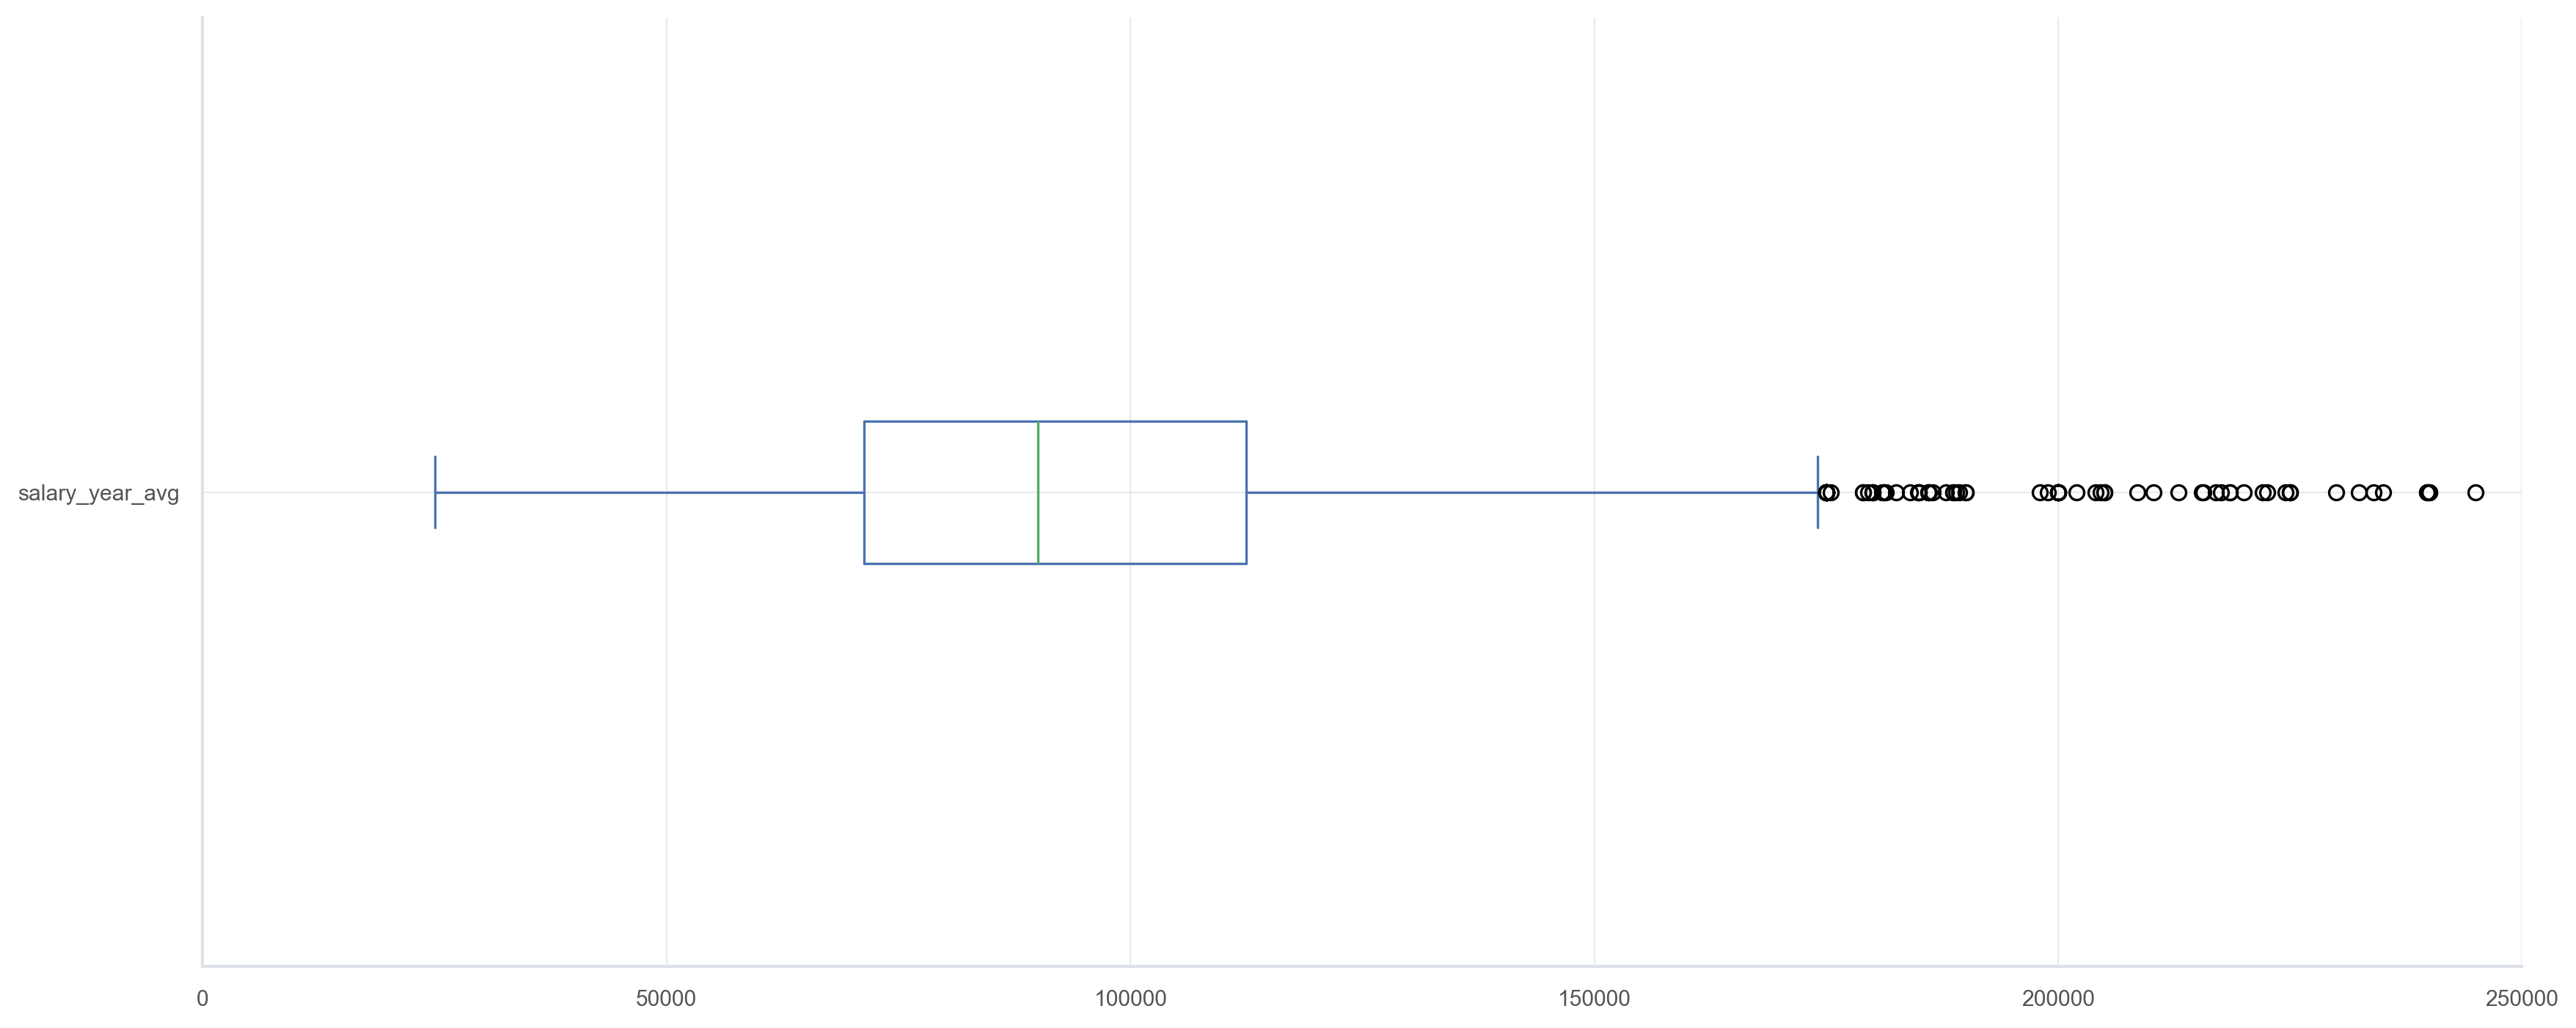

In [64]:
df_DA_US['salary_year_avg'].plot(kind='box', vert=False, xlim=(0, 250000))

C:\Users\abdel\AppData\Local\Temp\ipykernel_16500\416377011.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(job_list, labels=job_titles, vert=False)


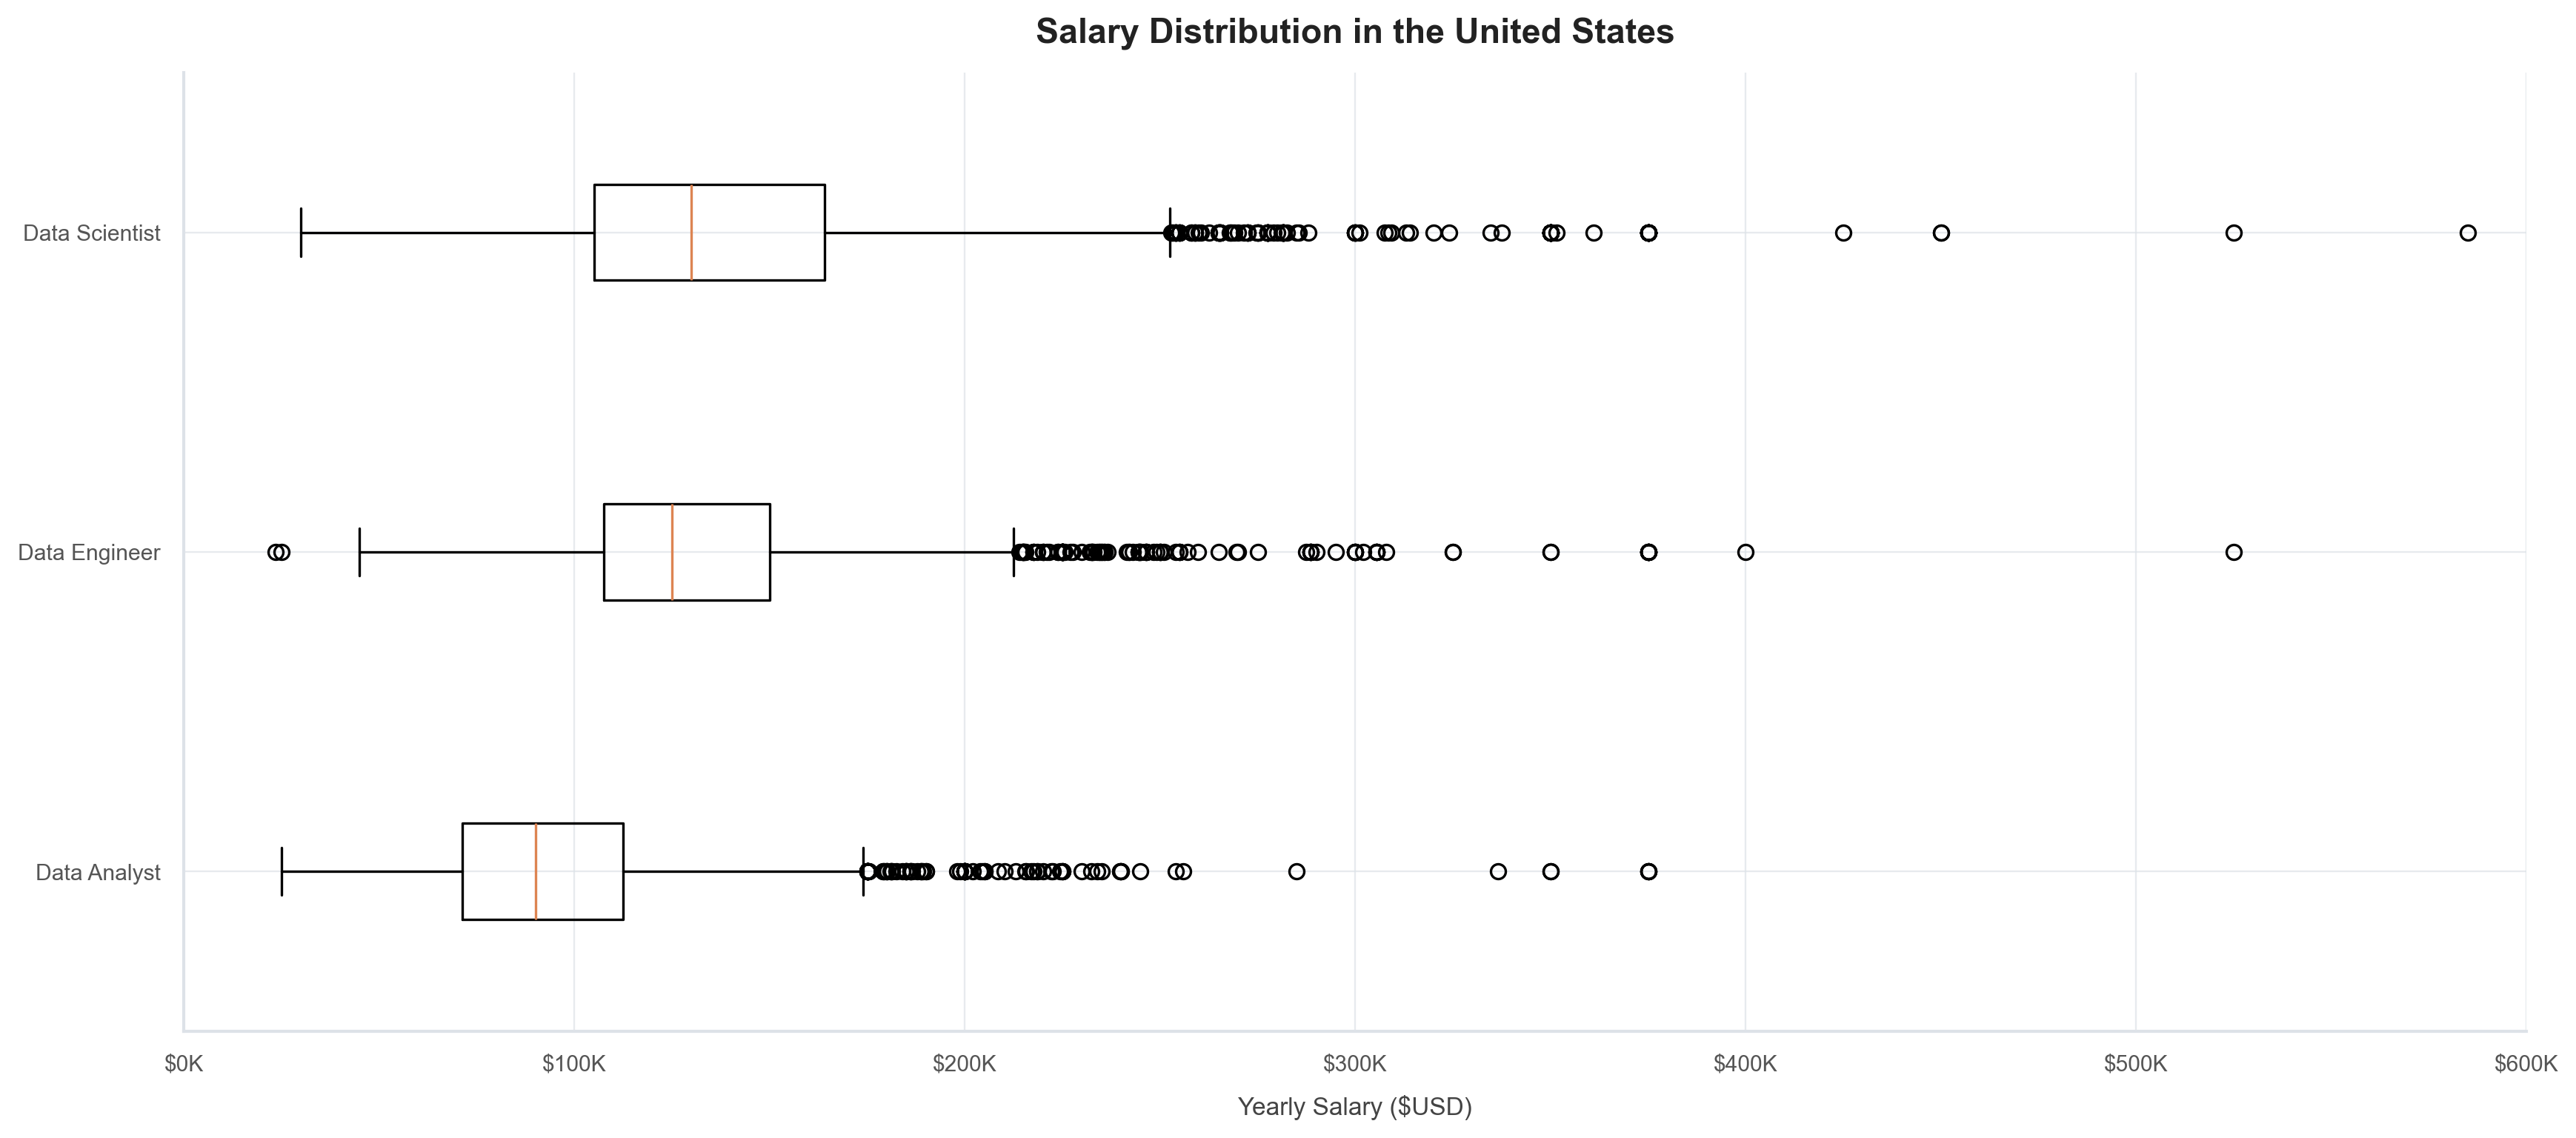

In [65]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

# filter the data to appropriate job _titles
df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')].copy()
df_US = df_US.dropna(subset=['salary_year_avg'])

job_list = [df_US[df_US['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

plt.boxplot(job_list, labels=job_titles, vert=False)
plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
plt.xlim(0,600000)

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))

plt.show()

# Exercice : Skill Pay Analysis.

In [66]:
df_DA_US = df_DA_US.explode('job_skills')

df_DA_US[['salary_year_avg', 'job_skills']]

,salary_year_avg,job_skills
109,89000.0,python
109,89000.0,r
109,89000.0,alteryx
109,89000.0,tableau
180,90250.0,excel
...,...,...
784882,87500.0,sql
784882,87500.0,vba
784882,87500.0,tableau
784882,87500.0,excel


In [67]:
df_DA_US_group = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])

df_DA_top_pay = df_DA_US_group.sort_values(by='median', ascending=False).head(10)

df_DA_top_skills = df_DA_US_group.sort_values(by='count', ascending=False).head(10).sort_values(by='median', ascending=False)



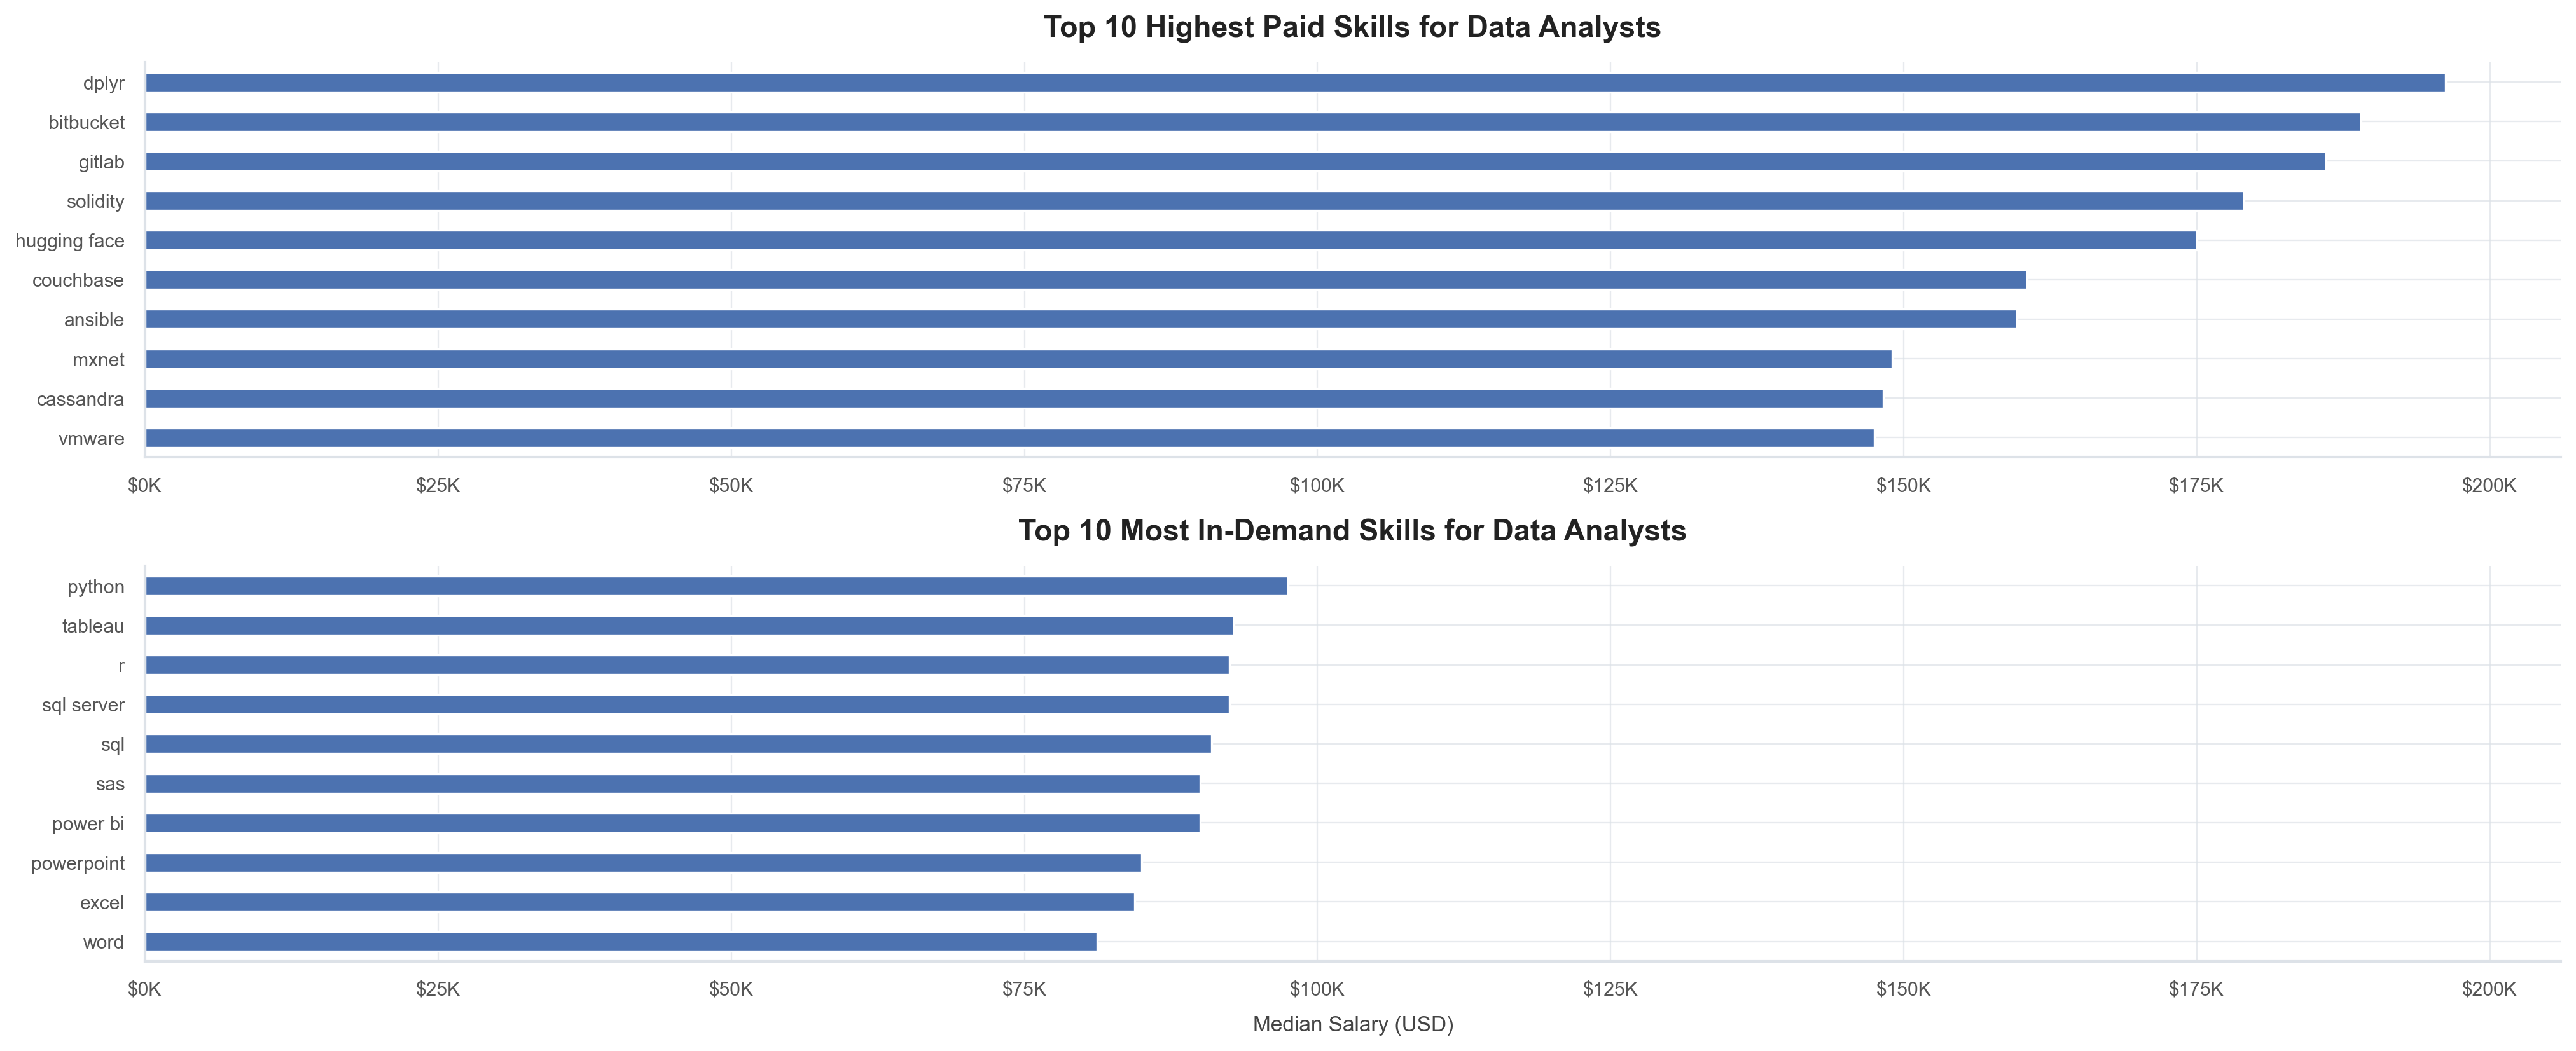

In [68]:
fig, ax = plt.subplots(2, 1)

df_DA_top_pay[::-1].plot(kind='barh', y='median', ax=ax[0], legend=False)
ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

df_DA_top_skills[::-1].plot(kind='barh', y='median', ax=ax[1],legend=False)
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].set_xlim(ax[0].get_xlim())
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

fig.tight_layout()

In [69]:
df_DA_top_pay, df_DA_top_skills

(              count    median
 job_skills                   
 dplyr             2  196250.0
 bitbucket         3  189000.0
 gitlab            3  186000.0
 solidity          1  179000.0
 hugging face      1  175000.0
 couchbase         1  160515.0
 ansible           1  159640.0
 mxnet             2  149000.0
 cassandra         6  148250.0
 vmware            1  147500.0,
             count    median
 job_skills                 
 python       1431  97500.00
 tableau      1364  92875.00
 r             893  92500.00
 sql server    286  92500.00
 sql          2508  91000.00
 sas           926  90000.00
 power bi      838  90000.00
 powerpoint    462  85000.00
 excel        1808  84392.00
 word          461  81194.75)

# SeaBorn : Intro

## SeaBorn Bar Plot.

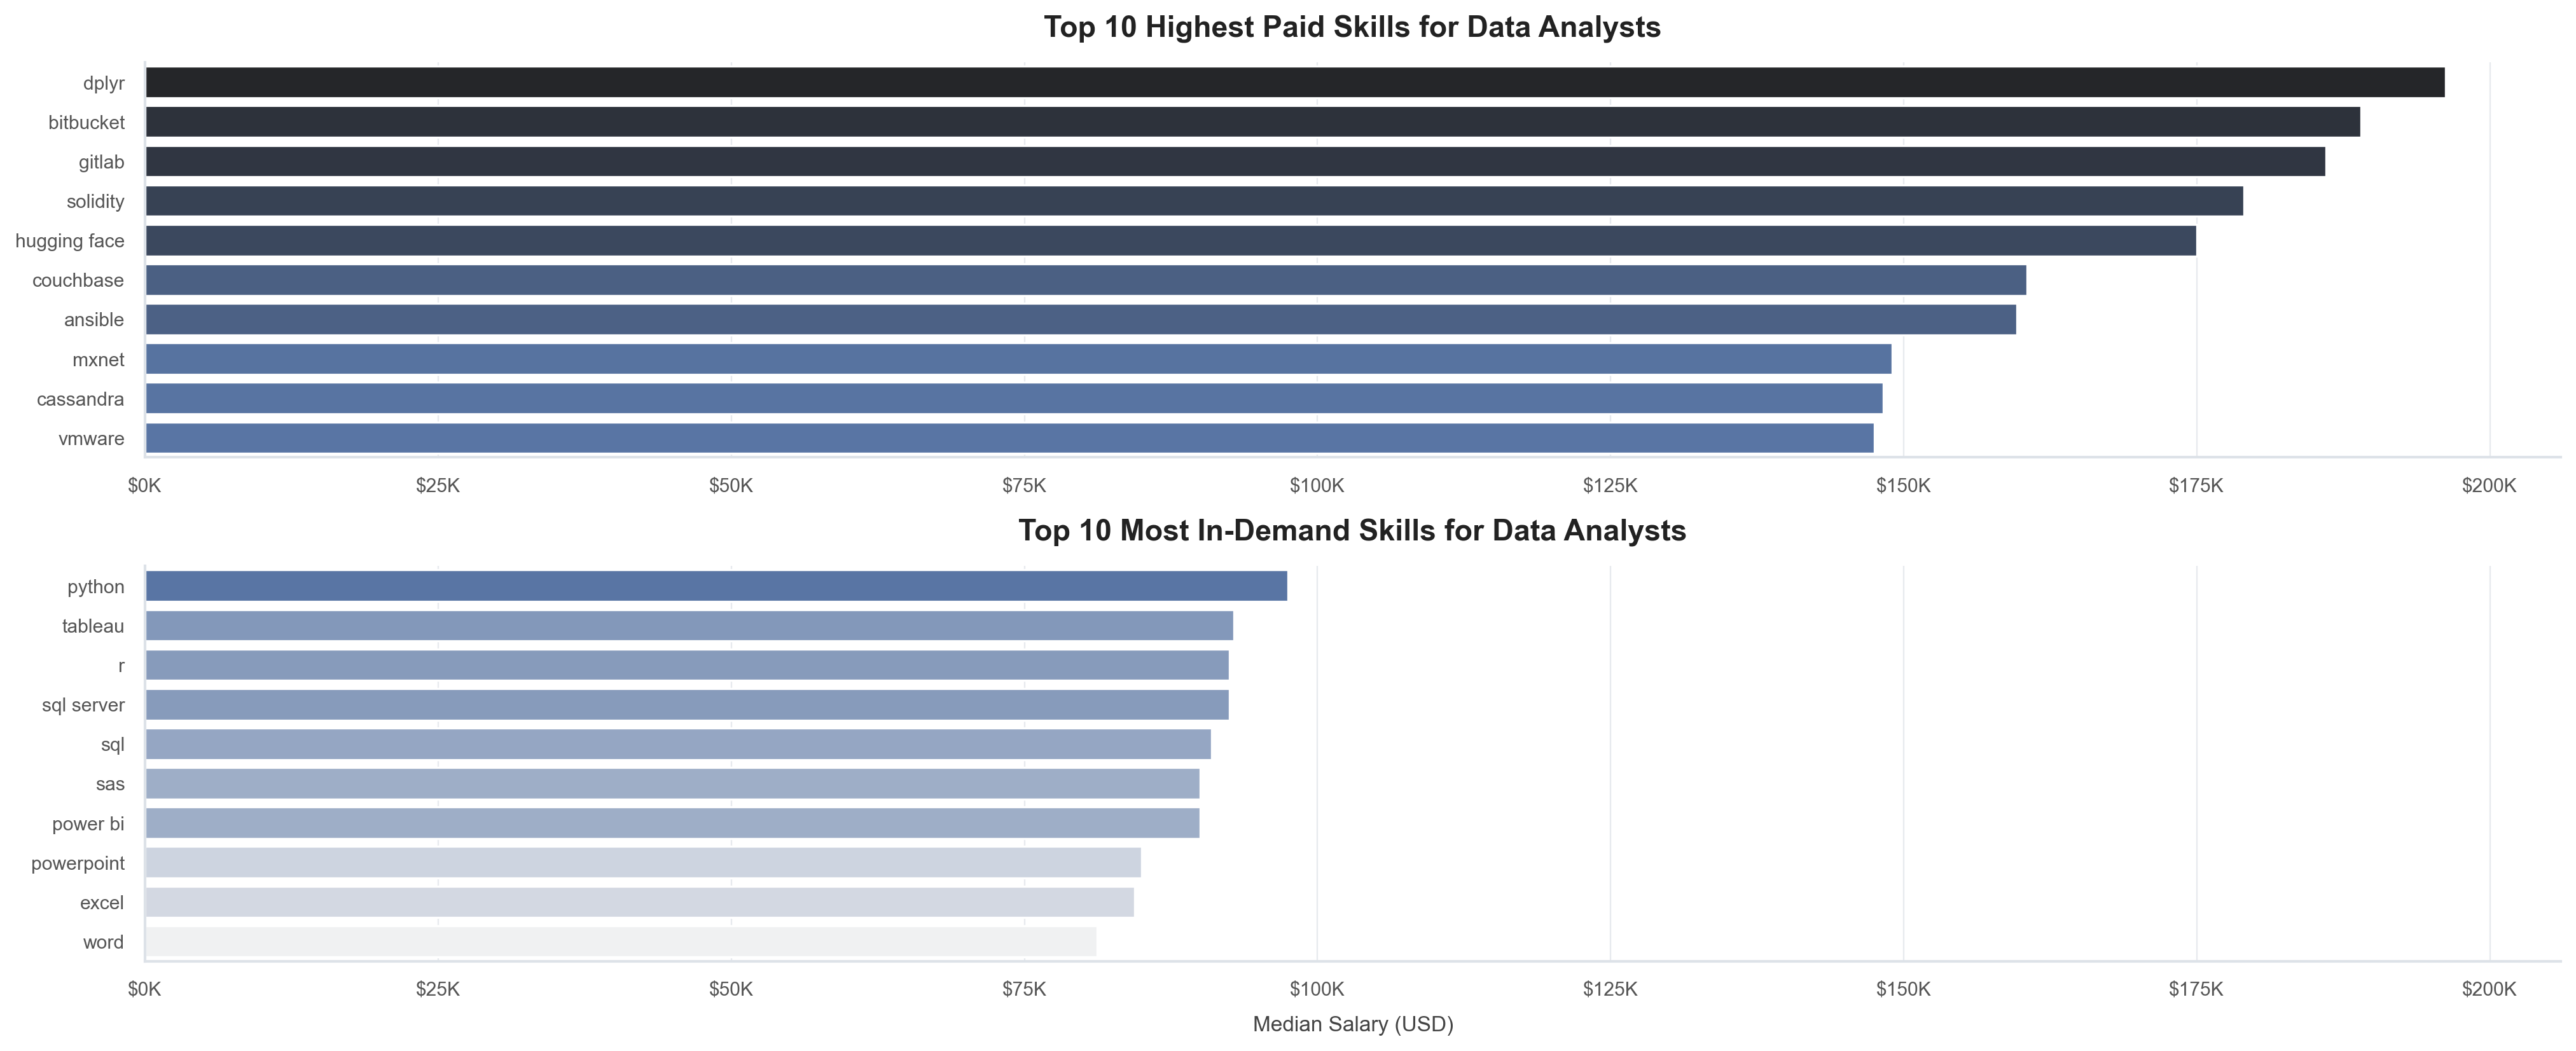

In [70]:
fig, ax = plt.subplots(2, 1)

# Top 10 Highest Paid Skills for Data Analysts
sns.barplot(data=df_DA_top_pay, x='median', y=df_DA_top_pay.index, ax=ax[0], hue='median', palette='dark:b_r', legend=False)

ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))


sns.barplot(data=df_DA_top_skills, x='median', y=df_DA_top_skills.index, ax=ax[1], hue='median', palette='light:b', legend=False)

ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].set_xlim(ax[0].get_xlim())  # Set the same x-axis limits as the first plot
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.tight_layout()
plt.show()

## SeaBorn DisPlot

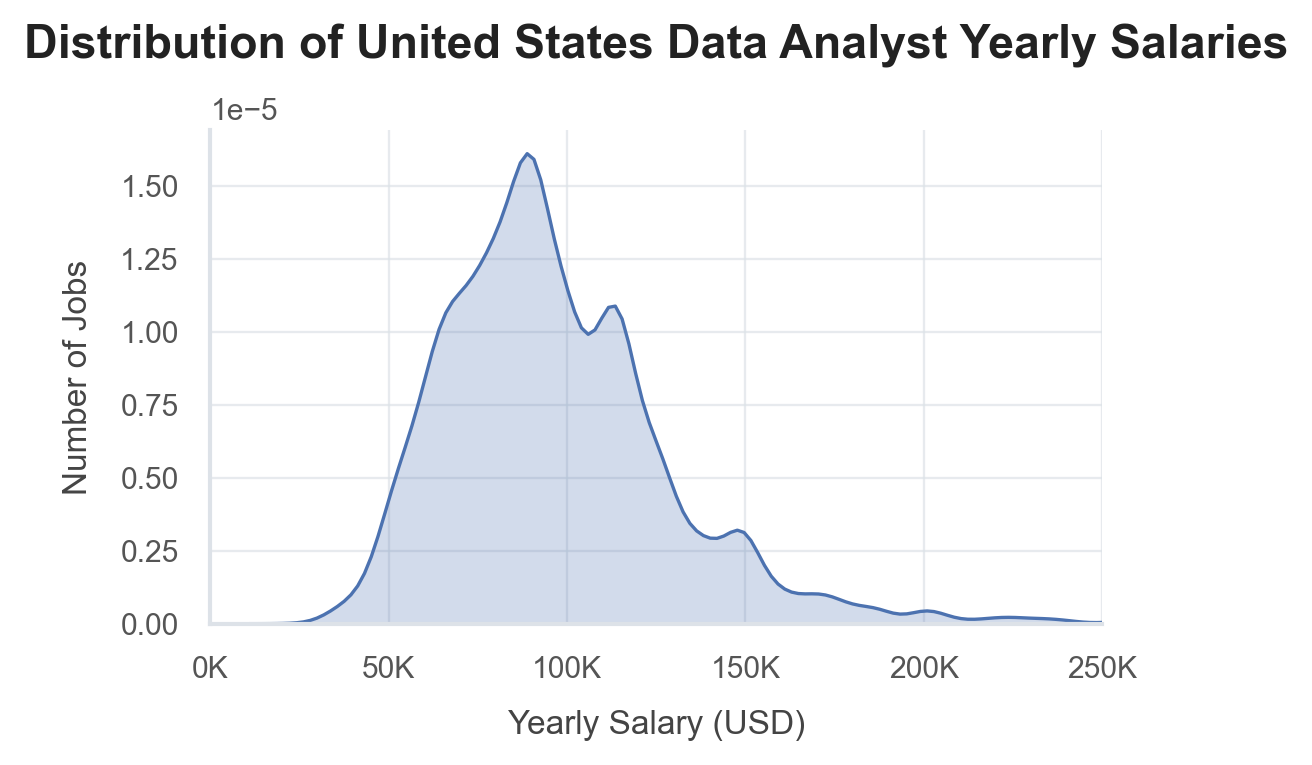

In [71]:
sns.displot(df_DA_US['salary_year_avg'], kind='kde', fill=True,  height=3, aspect=11/7)

plt.title('Distribution of United States Data Analyst Yearly Salaries')
plt.xlabel('Yearly Salary (USD)')
plt.ylabel('Number of Jobs')
plt.xlim(0,250000)

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'{int(y/1000)}K'))

plt.show()

## SeaBorn Boxplot

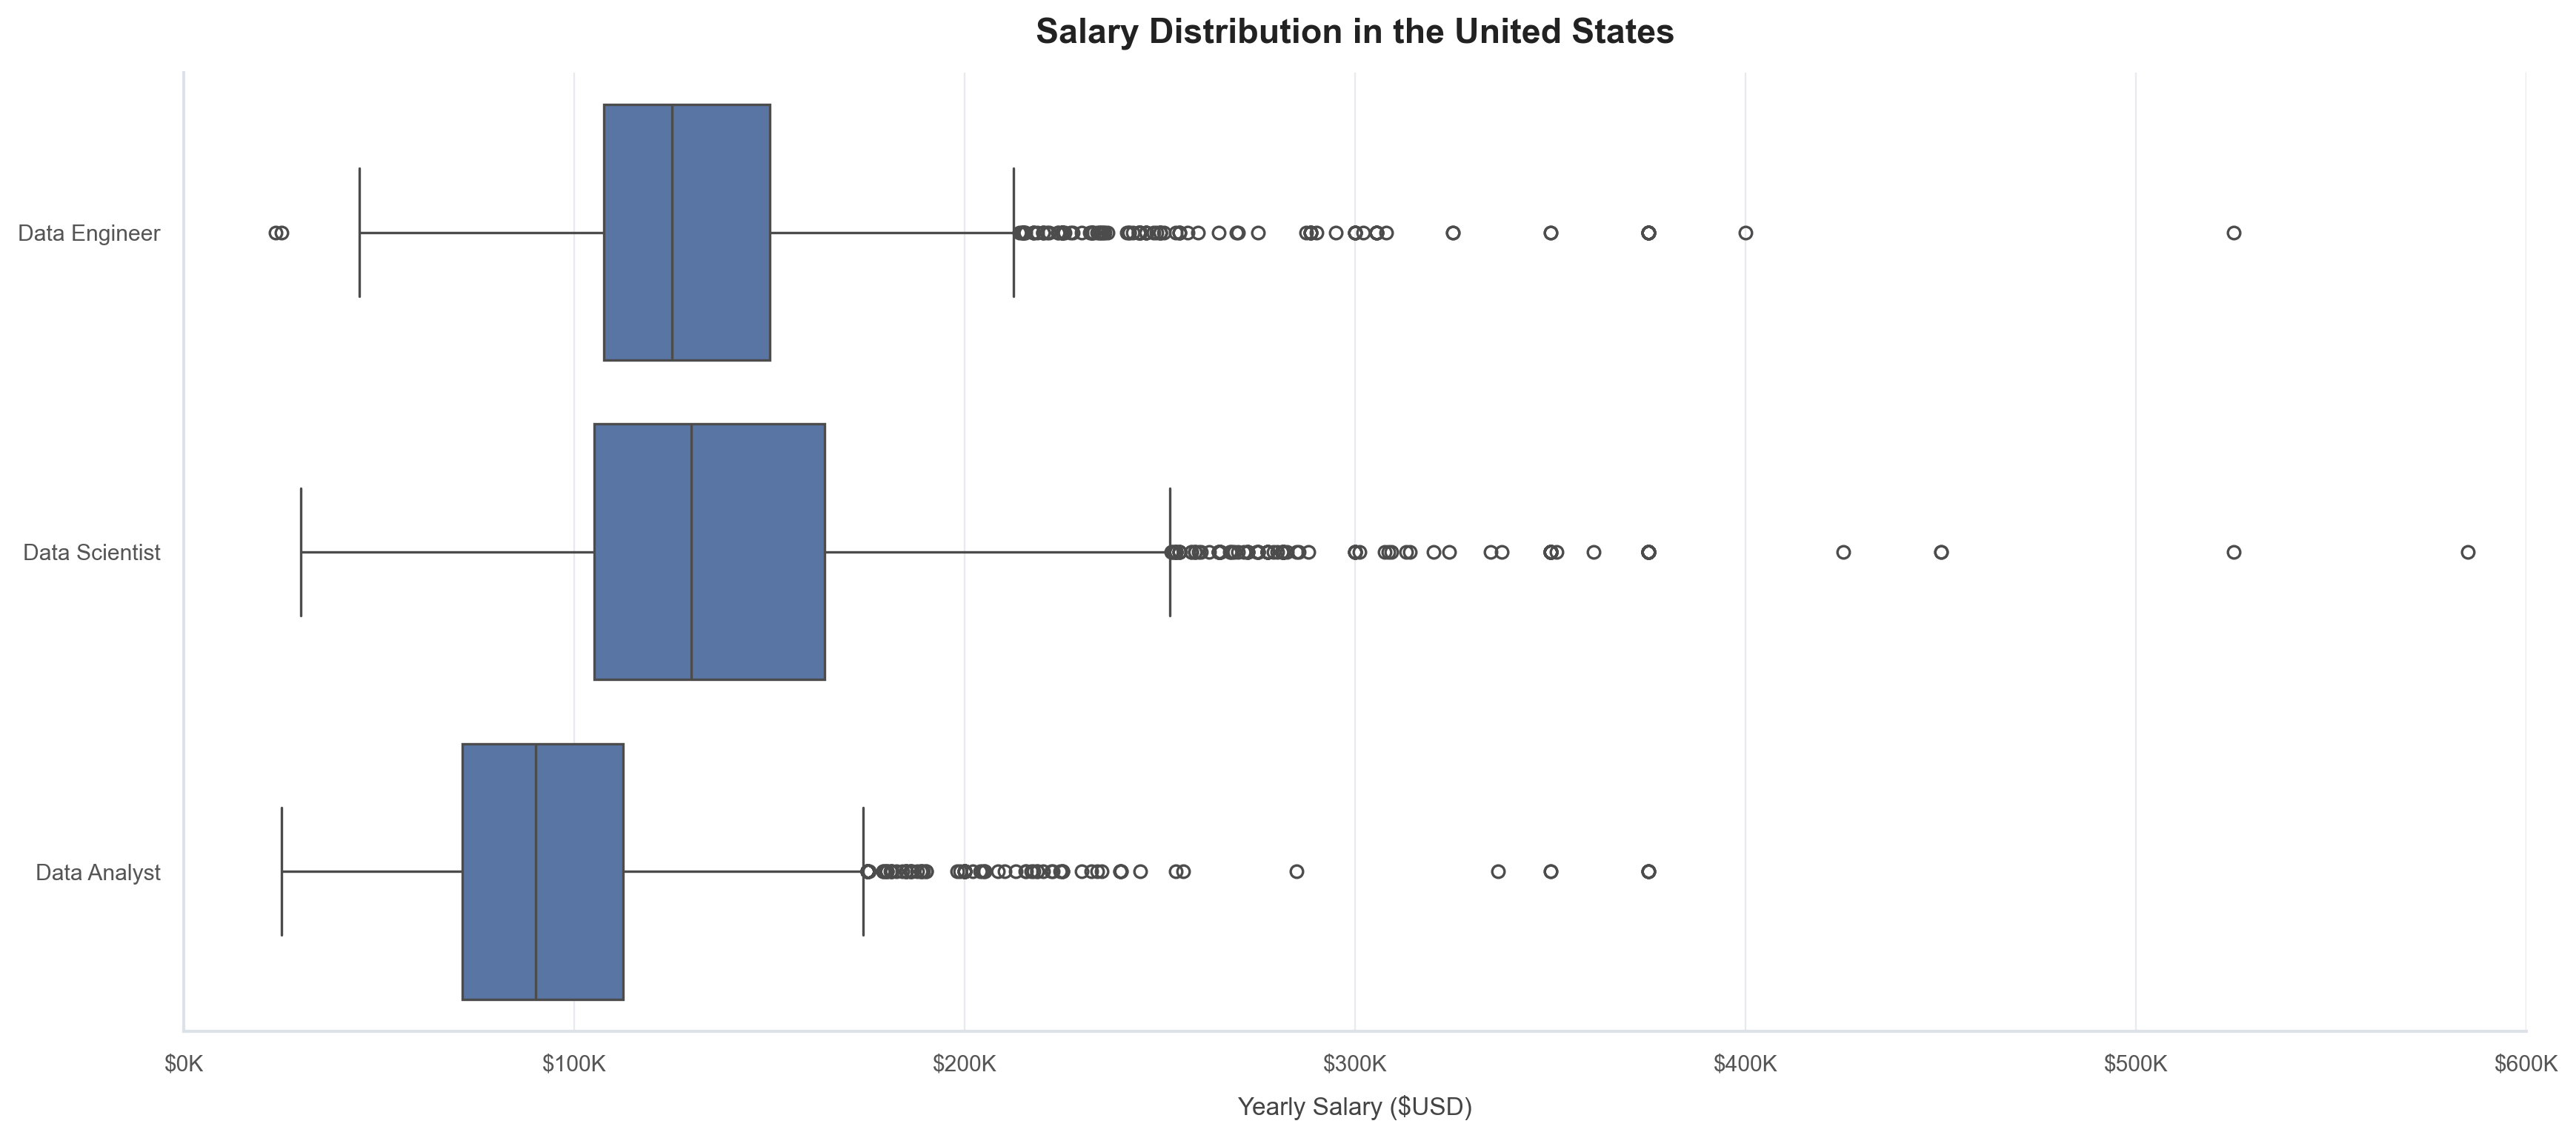

In [74]:

#plt.boxplot(job_list, labels=job_titles, vert=False)

sns.boxplot(data=df_US, x='salary_year_avg', y='job_title_short')

plt.title('Salary Distribution in the United States')
plt.xlabel('Yearly Salary ($USD)')
plt.ylabel('')
plt.xlim(0,600000)

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))

plt.show()